# Proyecto Final: Descubrimiento de Patrones de Fraude Bancario mediante el Modelo KDD
**Curso:** SINF-633 Análisis Exploratorio de Datos (EDA)  
**Estudiante:** Lucerito Chacón Matamoros  
**Institución:** Universidad CENFOTEC — 2026

### Contexto y Pregunta Central del Proyecto
En este cuaderno asumimos el rol de analista senior de prevención de fraude en una entidad bancaria costarricense. Aplicamos de forma reproducible las cinco etapas canónicas del modelo **Knowledge Discovery in Databases (KDD)** propuesto por Fayyad et al. (1996) —**Selección, Preprocesamiento, Transformación, Minería e Interpretación (SPTMI)**— sobre el conjunto de datos `transacciones_bancarias.csv` (5 000 registros y 11 variables).

> **Pregunta Estratégica Central:**  
> *¿Qué patrones permiten distinguir transacciones bancarias legítimas de fraudulentas, y cómo puede el banco operacionalizar esos patrones para reducir pérdidas sin degradar la experiencia del cliente legítimo?*

**Paleta Cromática Institucional y Financiera:**
* **Azul Marino Principal:** `#164a98`
* **Azul Corporativo Secundario:** `#006AEA`
* **Azul Medio / Claro:** `#2b93d1` / `#9CC8FF`
* **Gris Neutro:** `#7c7b75` / `#d2d2d2`
* **Alerta de Fraude:** `#C0392B`

In [ ]:
# PREPARAR LAS HERRAMIENTAS Y CONFIGURAR DETALLES Y COLORES
import os
import random
import warnings
warnings.simplefilter("ignore", DeprecationWarning)
from mlxtend.frequent_patterns import apriori, association_rules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Librerías de Scikit-Learn para Transformación y Minería (Etapas 3, 4 y 5)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix,
    classification_report, silhouette_score
)

In [ ]:
# Fijar semilla global para reproducibilidad estricta
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [ ]:
# Definir paleta cromática institucional y financiera (CENFOTEC - Banca)
BANK_PALETTE = ['#164a98', '#006AEA', '#2b93d1', '#9CC8FF', '#7c7b75', '#C0392B']
COLOR_PRIMARY = '#164a98'
COLOR_SECONDARY = '#006AEA'
COLOR_MID = '#2b93d1'
COLOR_LIGHT = '#9CC8FF'
COLOR_GRAY = '#7c7b75'
COLOR_FRAUD = '#C0392B'

sns.set_theme(style='whitegrid', palette= sns.color_palette(BANK_PALETTE))
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [ ]:
# Crear carpeta para exportar gráficos en alta resolución
os.makedirs('output', exist_ok=True)

print(f"Entorno configurado exitosamente | Semilla fijada en: {SEED}")
print(f"Versiones -> Pandas: {pd.__version__} | NumPy: {np.__version__} | Seaborn: {sns.__version__}")

Entorno configurado exitosamente | Semilla fijada en: 42
Versiones -> Pandas: 2.2.3 | NumPy: 2.1.3 | Seaborn: 0.13.2


## **Etapa 1 · Selección de Datos y Diagnóstico Estructural**
En la primera etapa del modelo KDD identificamos la estructura del conjunto de datos `transacciones_bancarias.csv`, auditamos los tipos de variables reconociendo fechas e identificadores, establecemos qué atributos aportan señal legítima para detectar el fraude antes de que ocurra (evitando fugas de información o variables sin poder de generalización) y analizamos el desbalance de la variable objetivo `es_fraude`.

In [ ]:
# ETAPA 1: CARGAR LA INFORMACIÓN Y EXPLORACIÓN ESTRUCTURAL
RUTA_DATOS = 'transacciones_bancarias.csv'
df_raw = pd.read_csv(RUTA_DATOS, parse_dates=['fecha_hora'])

print(f"Dataset cargado exitosamente: {df_raw.shape[0]:,} registros y {df_raw.shape[1]} columnas.\n")

Dataset cargado exitosamente: 5,000 registros y 11 columnas.



In [ ]:
print("--- Tipos de datos detectados (dtypes) ---")
print(df_raw.dtypes)

--- Tipos de datos detectados (dtypes) ---
id_transaccion                      int64
fecha_hora                 datetime64[ns]
id_cliente                          int64
edad_cliente                      float64
antiguedad_cuenta_meses             int64
tipo_transaccion                   object
monto                             float64
canal                              object
region                             object
estado_transaccion                 object
es_fraude                           int64
dtype: object


In [ ]:
print("\n--- Información estructural del DataFrame ---")
df_raw.info()


--- Información estructural del DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_transaccion           5000 non-null   int64         
 1   fecha_hora               5000 non-null   datetime64[ns]
 2   id_cliente               5000 non-null   int64         
 3   edad_cliente             4929 non-null   float64       
 4   antiguedad_cuenta_meses  5000 non-null   int64         
 5   tipo_transaccion         5000 non-null   object        
 6   monto                    5000 non-null   float64       
 7   canal                    4941 non-null   object        
 8   region                   4921 non-null   object        
 9   estado_transaccion       5000 non-null   object        
 10  es_fraude                5000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(4), obje

In [ ]:
print("\n--- Primeras 5 transacciones del registro ---")
display(df_raw.head())


--- Primeras 5 transacciones del registro ---


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,estado_transaccion,es_fraude
0,1,2024-08-29 17:11:00,845,59.00,134,Depósito,277.26,Teléfono,Alajuela,Completada,0
1,2,2024-07-11 23:18:00,1422,41.00,189,Retiro,21.38,Web,Alajuela,Completada,0
2,3,2024-05-01 13:13:00,41,28.00,8,Depósito,35.65,ATM,San José,Completada,0
3,4,2024-08-05 15:59:00,1475,56.00,121,Pago servicios,271.13,Web,Alajuela,Completada,0
4,5,2024-12-09 05:48:00,1462,18.00,110,Retiro,290.32,ATM,San José,Completada,0


In [ ]:
print("\n--- Muestra aleatoria de 5 transacciones (semilla 42) ---")
display(df_raw.sample(5, random_state=SEED))


--- Muestra aleatoria de 5 transacciones (semilla 42) ---


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,estado_transaccion,es_fraude
1501,1502,2024-12-30 15:38:00,302,66.00,163,Pago servicios,47.82,Teléfono,San José,Fallida,0
2586,2587,2024-06-05 09:27:00,932,26.00,189,Retiro,90.89,Web,San José,Completada,0
2653,2654,2024-05-14 11:13:00,310,24.00,91,Retiro,23.08,App móvil,San José,Completada,0
1055,1056,2024-07-05 07:36:00,535,34.00,149,Depósito,137.73,Web,Alajuela,Fallida,0
705,706,2024-08-19 18:55:00,1423,48.00,72,Depósito,128.13,ATM,Otras,Completada,0


In [ ]:
print("\n--- Resumen estadístico integral ---")
display(df_raw.describe(include='all').T)


--- Resumen estadístico integral ---


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id_transaccion,"5,000.00",NaN,NaN,NaN,"2,500.50",1.00,"1,250.75","2,500.50","3,750.25","5,000.00","1,443.52"
fecha_hora,5000,NaN,NaN,NaN,2024-06-30 23:18:18.444000,2024-01-01 00:13:00,2024-04-01 23:28:30,2024-07-01 10:54:00,2024-09-29 04:41:30,2024-12-30 19:57:00,NaN
id_cliente,"5,000.00",NaN,NaN,NaN,752.28,1.00,376.00,754.00,"1,134.00","1,498.00",435.14
edad_cliente,"4,929.00",NaN,NaN,NaN,39.72,18.00,31.00,40.00,48.00,84.00,12.57
antiguedad_cuenta_meses,"5,000.00",NaN,NaN,NaN,120.75,1.00,62.00,121.00,182.00,239.00,68.64
tipo_transaccion,5000,6,Transferencia,1237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monto,"5,000.00",NaN,NaN,NaN,"5,373.35",0.36,20.72,57.81,164.39,"487,155.05","40,408.35"
canal,4941,5,App móvil,1738,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,4921,5,San José,1947,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_transaccion,5000,4,Completada,4214,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Taxonomía de las 11 Variables y Criterio de Selección

| # | Variable | Tipo Estadístico | Dtype en Pandas | Decisión | Justificación Técnica y de Negocio |
|---|---|---|---|---|---|
| 1 | `id_transaccion` | Identificador único | `int64` | **Excluir** | Es una llave primaria secuencial (1 a 5 000) con cardinalidad máxima. No contiene patrón de comportamiento y conservarla introduciría ruido o sobreajuste artificial. |
| 2 | `fecha_hora` | Fecha / Hora | `datetime64[ns]` | **Incluir (para transformación)** | Indispensable en Etapa 3 para extraer patrones horarios (`hora_dia`, `es_noche`), ya que los ataques automatizados suelen concentrarse en la madrugada. Se descarta la estampa cruda tras extraer los atributos derivados. |
| 3 | `id_cliente` | Identificador nominal | `int64` | **Excluir** | Identifica a la persona pero no generaliza para clientes nuevos. Además, de acuerdo con la Ley N.° 8968 de Protección de Datos Personales en Costa Rica, su exclusión favorece la anonimización del modelo. |
| 4 | `edad_cliente` | Numérica continua (en años) | `float64` | **Incluir** | Permite capturar perfiles demográficos de vulnerabilidad (por ejemplo, ingeniería social en adultos mayores o cuentas jóvenes). Presenta 71 nulos (1.42%) que serán imputados. |
| 5 | `antiguedad_cuenta_meses` | Numérica discreta | `int64` | **Incluir** | El historial de relación con el banco (de 1 a 239 meses) ayuda a diferenciar cuentas consolidadas de cuentas recientes o comprometidas. |
| 6 | `tipo_transaccion` | Categórica nominal | `object` | **Incluir** | Distingue la naturaleza operativa (Transferencia, Depósito, Pago servicios, Retiro, Compra, Pago préstamo), permitiendo identificar operaciones preferidas por los defraudadores. |
| 7 | `monto` | Numérica continua (USD) | `float64` | **Incluir** | Es el indicador financiero central (rango de $0.36 a $487,155.05). Los montos atípicos suelen reflejar intentos de vaciamiento de cuenta. |
| 8 | `canal` | Categórica nominal | `object` | **Incluir** | Registra el punto de contacto (App móvil, Web, ATM, Teléfono, Sucursal). Presenta 59 nulos (1.18%) y es clave para evaluar exposición digital vs física. |
| 9 | `region` | Categórica nominal | `object` | **Incluir** | Ubicación geográfica (San José, Alajuela, Cartago, Heredia, Otras). Presenta 79 nulos (1.58%) y permite detectar focos regionales de incidencia. |
| 10 | `estado_transaccion` | Categórica nominal | `object` | **Excluir** | Representa el resultado *post-ejecución* de la operación (Completada, Pendiente, Fallida, Reversada). En un motor de prevención en tiempo real (scoring pre-autorización), el estado final aún no existe al evaluar la transacción; incluirlo constituiría fuga de información (*data leakage*) operativa. |
| 11 | `es_fraude` | Booleana / Binaria (Objetivo) | `int64` | **Incluir (Target `y`)** | Variable dependiente que indica si la transacción fue legítima (`0`) o fraudulenta (`1`). |

In [ ]:
# SELECCIÓN DEL SUBCONJUNTO DE COLUMNAS RELEVANTES Y TASA DE FRAUDE
columnas_relevantes = [
    'fecha_hora', 'edad_cliente', 'antiguedad_cuenta_meses',
    'tipo_transaccion', 'monto', 'canal', 'region', 'es_fraude'
]
df_sel = df_raw[columnas_relevantes].copy()

print(f"Columnas seleccionadas ({df_sel.shape[1]}): {columnas_relevantes}")
print(f"Columnas excluidas (3): ['id_transaccion', 'id_cliente', 'estado_transaccion']\n")

Columnas seleccionadas (8): ['fecha_hora', 'edad_cliente', 'antiguedad_cuenta_meses', 'tipo_transaccion', 'monto', 'canal', 'region', 'es_fraude']
Columnas excluidas (3): ['id_transaccion', 'id_cliente', 'estado_transaccion']



In [ ]:
# Cálculo de la tasa global de fraude
conteo_clases = df_sel['es_fraude'].value_counts()
proporcion_clases = df_sel['es_fraude'].value_counts(normalize=True) * 100
tasa_fraude_global = df_sel['es_fraude'].mean() * 100

resumen_clases = pd.DataFrame({
    'Etiqueta': ['Legítima (0)', 'Fraudulenta (1)'],
    'Cantidad': conteo_clases.values,
    'Porcentaje (%)': proporcion_clases.values.round(2)
})
display(resumen_clases)
print(f"Tasa global de fraude en el banco: {tasa_fraude_global:.2f}% (Ratio aproximado de 1 fraude por cada {conteo_clases[0]/conteo_clases[1]:.1f} legítimas)")

,Etiqueta,Cantidad,Porcentaje (%)
0,Legítima (0),4891,97.82
1,Fraudulenta (1),109,2.18


Tasa global de fraude en el banco: 2.18% (Ratio aproximado de 1 fraude por cada 44.9 legítimas)


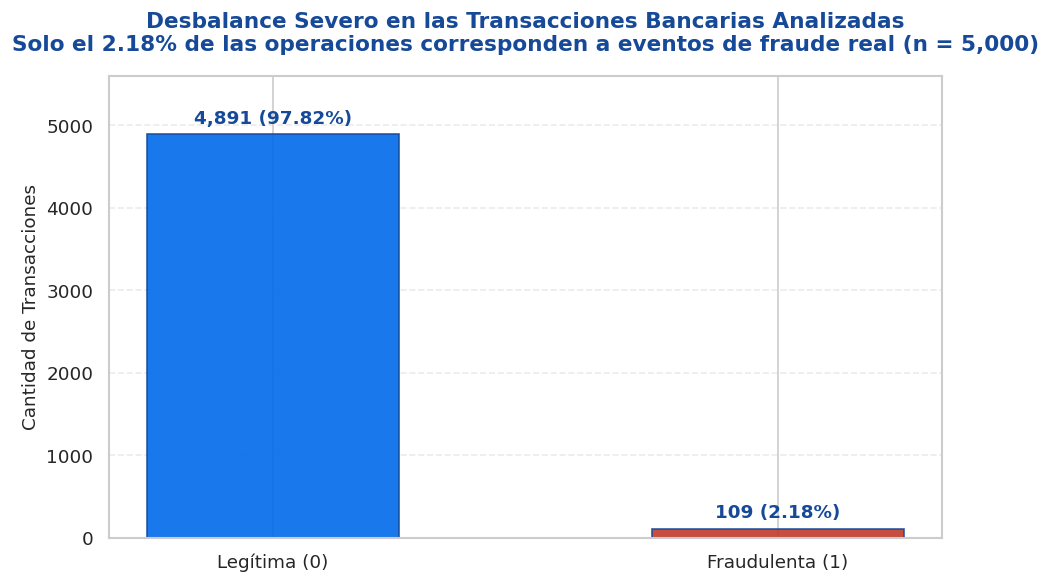

In [ ]:
# Visualización del Desbalance de Clases
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(
    resumen_clases['Etiqueta'],
    resumen_clases['Cantidad'],
    color=[COLOR_SECONDARY, COLOR_FRAUD],
    edgecolor=COLOR_PRIMARY,
    width=0.5,
    alpha=0.9
)

for barra, pct in zip(barras, resumen_clases['Porcentaje (%)']):
    altura = barra.get_height()
    ax.annotate(
        f"{int(altura):,} ({pct:.2f}%)",
        xy=(barra.get_x() + barra.get_width() / 2, altura + 80),
        ha='center', va='bottom', fontsize=11, fontweight='bold', color=COLOR_PRIMARY
    )

ax.set_title(
    'Desbalance Severo en las Transacciones Bancarias Analizadas\nSolo el 2.18% de las operaciones corresponden a eventos de fraude real (n = 5,000)',
    fontsize=13, fontweight='bold', color=COLOR_PRIMARY, pad=15
)
ax.set_ylabel('Cantidad de Transacciones', fontsize=11)
ax.set_ylim(0, 5600)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('output/01_desbalance_clases.png', dpi=150, facecolor='white')
plt.show()

**Interpretación del gráfico:**
* **¿Qué se ve en el gráfico?** El gráfico de barras compara el volumen absoluto y relativo de transacciones legítimas frente a las fraudulentas. De las 5 000 operaciones registradas, **4 891 (97.82%)** son legítimas y únicamente **109 (2.18%)** corresponden a fraudes confirmados, lo que evidencia una relación de asimetría de clases de **44.9 a 1**.
* **¿Qué significa para la entidad bancaria?** Este fuerte desbalance es el comportamiento natural de la banca real, pero representa una trampa metodológica crítica para el modelado: si entrenáramos un clasificador ingenuo que prediga siempre *"Transacción Legítima"*, alcanzaría un **97.82% de exactitud (*accuracy*)** sin detectar ni un solo fraude, exponiendo al banco a pérdidas millonarias. Por esta razón, en este proyecto tomaremos tres medidas técnicas obligatorias: (1) usar partición estratificada (`stratify=y`) al dividir entrenamiento y prueba, (2) penalizar los errores de la clase minoritaria mediante `class_weight='balanced'`, y (3) priorizar las métricas de **Recall (Sensibilidad)**, **F1-Score** y **AUC-ROC** por encima del *accuracy* convencional.

## **Etapa 2 · Preprocesamiento: Limpieza, Imputación, Outliers y Asimetría**
En la segunda etapa del KDD auditamos la calidad de los datos seleccionados siguiendo el protocolo **L-I-D (*Localizar, Imputar y Documentar*)**. Diagnosticamos los valores faltantes y su mecanismo subyacente, evaluamos la presencia de registros duplicados, ejecutamos la detección de valores atípicos mediante el rango intercuartílico ($\text{IQR}, k = 1.5$) comparando su tasa de fraude frente a las operaciones normales, y corregimos la asimetría extrema de la variable `monto` con `np.log1p()`.

In [ ]:
# ETAPA 2.1: DIAGNÓSTICO E IMPUTACIÓN DE VALORES NULOS

df_prep = df_sel.copy()

# 1. Reporte detallado de nulos por columna
nulos_abs = df_prep.isna().sum()
nulos_pct = (df_prep.isna().mean() * 100).round(2)
reporte_nulos = pd.DataFrame({
    'Tipo de Dato': df_prep.dtypes,
    'Nulos (Cantidad)': nulos_abs,
    'Nulos (%)': nulos_pct
}).sort_values(by='Nulos (Cantidad)', ascending=False)

print("--- Diagnóstico de Valores Faltantes por Columna ---")
display(reporte_nulos)
print(f"Total de celdas vacías en el dataset: {nulos_abs.sum()} ({(df_prep.isna().any(axis=1).mean()*100):.2f}% de las filas tienen algún nulo)\n")

--- Diagnóstico de Valores Faltantes por Columna ---


,Tipo de Dato,Nulos (Cantidad),Nulos (%)
region,object,79,1.58
edad_cliente,float64,71,1.42
canal,object,59,1.18
fecha_hora,datetime64[ns],0,0.00
tipo_transaccion,object,0,0.00
antiguedad_cuenta_meses,int64,0,0.00
monto,float64,0,0.00
es_fraude,int64,0,0.00


Total de celdas vacías en el dataset: 209 (4.12% de las filas tienen algún nulo)



In [ ]:
# Revisar estadísticos previos de las columnas con nulos para justificar la imputación
mediana_edad = df_prep['edad_cliente'].median()
media_edad = df_prep['edad_cliente'].mean()
skew_edad = df_prep['edad_cliente'].skew()
moda_canal = df_prep['canal'].mode()[0]
moda_region = df_prep['region'].mode()[0]

print(f"Edad Cliente -> Media: {media_edad:.2f} | Mediana: {mediana_edad:.2f} | Asimetría (Skew): {skew_edad:.2f}")
print(f"Canal        -> Moda: '{moda_canal}' (frecuencia: {df_prep['canal'].value_counts().iloc[0]} de {df_prep['canal'].count()})")
print(f"Región       -> Moda: '{moda_region}' (frecuencia: {df_prep['region'].value_counts().iloc[0]} de {df_prep['region'].count()})\n")

Edad Cliente -> Media: 39.72 | Mediana: 40.00 | Asimetría (Skew): 0.22
Canal        -> Moda: 'App móvil' (frecuencia: 1738 de 4941)
Región       -> Moda: 'San José' (frecuencia: 1947 de 4921)



In [ ]:
# 2. Aplicación de la estrategia de imputación
df_prep['edad_cliente'] = df_prep['edad_cliente'].fillna(mediana_edad)
df_prep['canal'] = df_prep['canal'].fillna(moda_canal)
df_prep['region'] = df_prep['region'].fillna(moda_region)

In [ ]:
# Verificación de calidad post-imputación
assert df_prep.isna().sum().sum() == 0, "Error: Aún quedan valores nulos"
print("Verificación exitosa: Nulos restantes en el dataset =", df_prep.isna().sum().sum())

Verificación exitosa: Nulos restantes en el dataset = 0


### Justificación de la Estrategia de Imputación Aplicada
1. **Diagnóstico del volumen y mecanismo (3M):** Las únicas tres columnas afectadas son `region` (**79 nulos, 1.58%**), `edad_cliente` (**71 nulos, 1.42%**) y `canal` (**59 nulos, 1.18%**). Ninguna columna supera el umbral crítico del 5% de faltantes. Al cruzar las filas con nulos contra `es_fraude`, solo 1 de los 209 valores faltantes coincide con un fraude, por lo que asumimos un mecanismo **MAR (*Missing At Random*)** u omisión operativa de captura sin sesgo oculto severo. Eliminar las filas con `dropna()` nos haría perder más de 200 transacciones válidas innecesariamente.
2. **Imputación de `edad_cliente` con la Mediana (`40.0` años):** Se prefiere la **mediana** sobre la media (`39.72` años) siguiendo el principio de robustez de Tukey: la mediana es inmune a valores extremos superiores (clientes de hasta 84 años presentes en la muestra) y preserva un valor entero natural para la edad.
3. **Imputación de `canal` (`App móvil`) y `region` (`San José`) con la Moda:** Al tratarse de variables **categóricas nominales** con menos del 1.6% de datos faltantes, las medidas aritméticas no son aplicables. La imputación mediante el valor más frecuente (**moda**) mantiene intacta la estructura de proporciones de las categorías dominantes sin crear categorías artificiales con muestras minúsculas que generen columnas espurias durante el *One-Hot Encoding*.

In [ ]:
# ETAPA 2.2: DETECCIÓN Y ELIMINACIÓN DE DUPLICADOS

dup_absolutos_raw = df_raw.duplicated().sum()
dup_absolutos_prep = df_prep.duplicated().sum()
dup_clave_operativa = df_raw.duplicated(subset=['id_cliente', 'fecha_hora', 'monto']).sum()

print(f"Filas completamente duplicadas (dataset original): {dup_absolutos_raw}")
print(f"Filas completamente duplicadas (subconjunto seleccionado): {dup_absolutos_prep}")
print(f"Duplicados parciales por clave lógica (id_cliente + fecha_hora + monto): {dup_clave_operativa}")

filas_antes = len(df_prep)
df_prep = df_prep.drop_duplicates().reset_index(drop=True)
filas_despues = len(df_prep)

print(f"Registros antes de deduplicar: {filas_antes:,} | Después de deduplicar: {filas_despues:,} (Eliminados: {filas_antes - filas_despues})")

Filas completamente duplicadas (dataset original): 0
Filas completamente duplicadas (subconjunto seleccionado): 0
Duplicados parciales por clave lógica (id_cliente + fecha_hora + monto): 0
Registros antes de deduplicar: 5,000 | Después de deduplicar: 5,000 (Eliminados: 0)


In [ ]:
# ETAPA 2.3: DETECCIÓN DE OUTLIERS (MÉTODO IQR, k=1.5) Y TASA DE FRAUDE

def detectar_outliers_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - k * iqr
    lim_sup = q3 + k * iqr
    mask = (serie < lim_inf) | (serie > lim_sup)
    return mask, lim_inf, lim_sup, q1, q3, iqr

vars_numericas_orig = ['edad_cliente', 'antiguedad_cuenta_meses', 'monto']
resultados_iqr = []

for col in vars_numericas_orig:
    mask_out, li, ls, q1, q3, iqr = detectar_outliers_iqr(df_prep[col], k=1.5)
    n_out = mask_out.sum()
    pct_out = mask_out.mean() * 100
    fraudes_en_out = df_prep.loc[mask_out, 'es_fraude'].sum() if n_out > 0 else 0
    tasa_fraude_out = (df_prep.loc[mask_out, 'es_fraude'].mean() * 100) if n_out > 0 else 0.0
    tasa_fraude_norm = df_prep.loc[~mask_out, 'es_fraude'].mean() * 100

    resultados_iqr.append({
        'Variable': col,
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'IQR': iqr,
        'Límite Inferior': li,
        'Límite Superior': ls,
        'Outliers (n)': n_out,
        'Outliers (%)': pct_out,
        'Fraudes en Outliers (n)': fraudes_en_out,
        'Tasa Fraude Outliers (%)': tasa_fraude_out,
        'Tasa Fraude Normales (%)': tasa_fraude_norm
    })

df_resumen_iqr = pd.DataFrame(resultados_iqr)
print("--- Análisis Comparativo de Outliers por Método IQR (k = 1.5) ---")
display(df_resumen_iqr)

--- Análisis Comparativo de Outliers por Método IQR (k = 1.5) ---


,Variable,Q1 (25%),Q3 (75%),IQR,Límite Inferior,Límite Superior,Outliers (n),Outliers (%),Fraudes en Outliers (n),Tasa Fraude Outliers (%),Tasa Fraude Normales (%)
0,edad_cliente,31.00,48.00,17.00,5.50,73.50,18,0.36,0,0.00,2.19
1,antiguedad_cuenta_meses,62.00,182.00,120.00,-118.00,362.00,0,0.00,0,0.00,2.18
2,monto,20.72,164.39,143.68,-194.80,379.91,584,11.68,81,13.87,0.63


In [ ]:
# ETAPA 2.4: TRANSFORMACIÓN LOGARÍTMICA np.log1p() EN MONTO Y VISUALIZACIÓN

df_prep['monto_log'] = np.log1p(df_prep['monto'])

print("--- Impacto de la Transformación Logarítmica sobre 'monto' ---")
print(f"Monto Original -> Media: ${df_prep['monto'].mean():,.2f} | Mediana: ${df_prep['monto'].median():,.2f} | Skewness: {df_prep['monto'].skew():.2f} | Kurtosis: {df_prep['monto'].kurt():.2f}")
print(f"Monto Log1p    -> Media: {df_prep['monto_log'].mean():.2f}      | Mediana: {df_prep['monto_log'].median():.2f}      | Skewness: {df_prep['monto_log'].skew():.2f} | Kurtosis: {df_prep['monto_log'].kurt():.2f}")

--- Impacto de la Transformación Logarítmica sobre 'monto' ---
Monto Original -> Media: $5,373.35 | Mediana: $57.81 | Skewness: 8.66 | Kurtosis: 79.08
Monto Log1p    -> Media: 4.23      | Mediana: 4.07      | Skewness: 1.64 | Kurtosis: 5.84


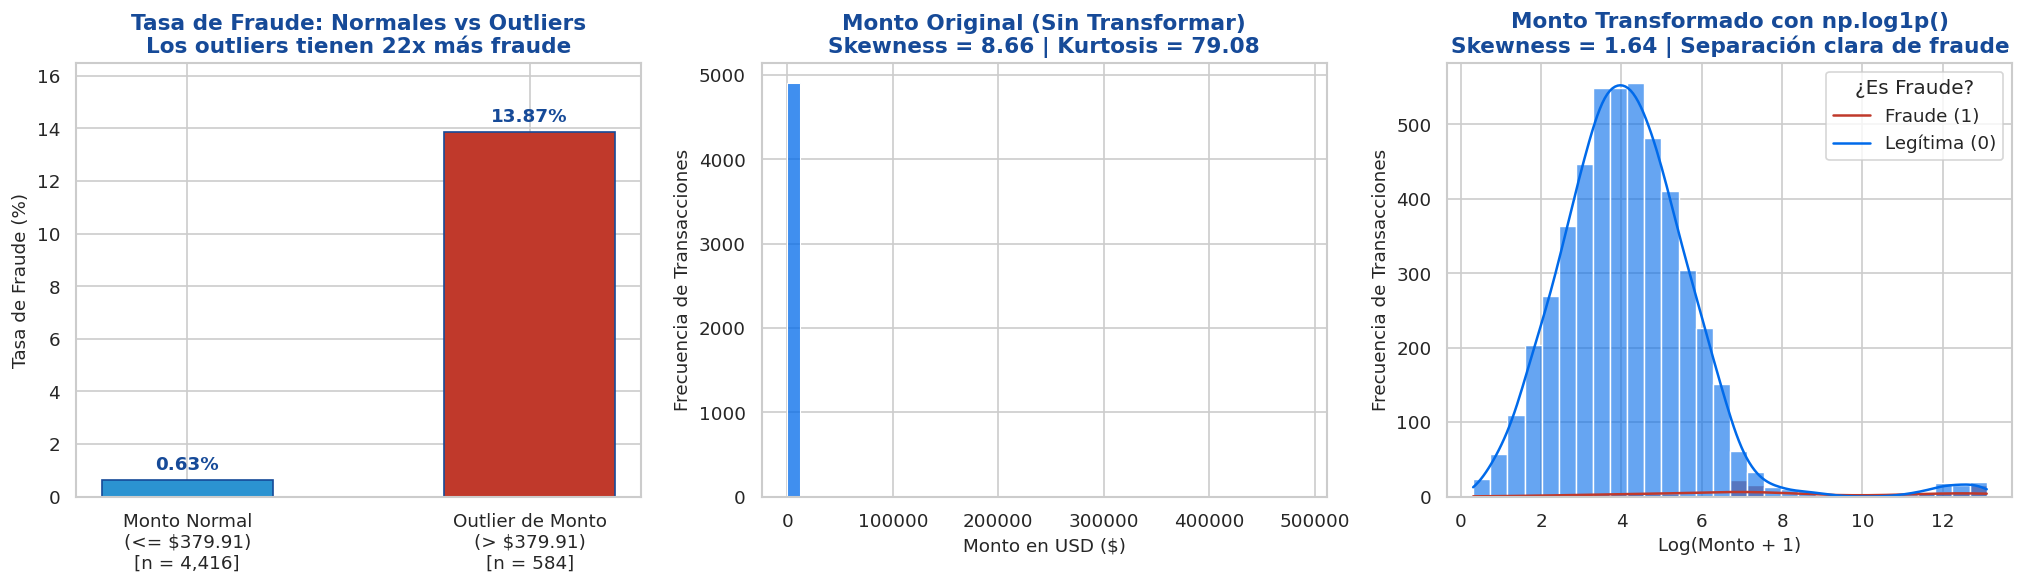

In [ ]:
# Gráfico triple: (1) Tasa de fraude en Outliers vs Normales de monto, (2) Distribución monto original, (3) Distribución monto_log
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Subgráfico 1: Comparación de tasa de fraude en Outliers de Monto vs Normales
tasas_monto = [0.63, 13.87]
etiquetas_monto = ['Monto Normal\n(<= $379.91)\n[n = 4,416]', 'Outlier de Monto\n(> $379.91)\n[n = 584]']
barras_out = axes[0].bar(etiquetas_monto, tasas_monto, color=[COLOR_MID, COLOR_FRAUD], edgecolor=COLOR_PRIMARY, width=0.5)
for b, t in zip(barras_out, tasas_monto):
    axes[0].annotate(f"{t:.2f}%", xy=(b.get_x() + b.get_width()/2, b.get_height() + 0.4),
                     ha='center', fontweight='bold', color=COLOR_PRIMARY)
axes[0].set_title('Tasa de Fraude: Normales vs Outliers\nLos outliers tienen 22x más fraude', fontweight='bold', color=COLOR_PRIMARY)
axes[0].set_ylabel('Tasa de Fraude (%)')
axes[0].set_ylim(0, 16.5)

# Subgráfico 2: Histograma de monto original (asimetría severa)
sns.histplot(df_prep['monto'], bins=40, color=COLOR_SECONDARY, ax=axes[1], kde=False)
axes[1].set_title(f"Monto Original (Sin Transformar)\nSkewness = {df_prep['monto'].skew():.2f} | Kurtosis = {df_prep['monto'].kurt():.2f}", fontweight='bold', color=COLOR_PRIMARY)
axes[1].set_xlabel('Monto en USD ($)')
axes[1].set_ylabel('Frecuencia de Transacciones')

# Subgráfico 3: Histograma + KDE de monto_log diferenciando Fraude
sns.histplot(data=df_prep, x='monto_log', hue='es_fraude', bins=30, kde=True,
             palette={0: COLOR_SECONDARY, 1: COLOR_FRAUD}, alpha=0.6, ax=axes[2])
axes[2].set_title(f"Monto Transformado con np.log1p()\nSkewness = {df_prep['monto_log'].skew():.2f} | Separación clara de fraude", fontweight='bold', color=COLOR_PRIMARY)
axes[2].set_xlabel('Log(Monto + 1)')
axes[2].set_ylabel('Frecuencia de Transacciones')
axes[2].legend(title='¿Es Fraude?', labels=['Fraude (1)', 'Legítima (0)'])

plt.tight_layout()
plt.savefig('output/02_outliers_y_transformacion_monto.png', dpi=150, facecolor='white')
plt.show()

**Interpretación del gráfico y Justificación del Tratamiento de Outliers (Regla COCOW):**
* **¿Qué se ve en el gráfico?** En el panel izquierdo observamos que las **584 transacciones** detectadas como valores atípicos de monto (`monto > $379.91`) presentan una **tasa de fraude del 13.87% (81 de los 109 fraudes totales del banco)**, mientras que en las 4 416 transacciones de monto normal la tasa de fraude es de apenas **0.63%**. En el panel central vemos cómo el monto original tiene una asimetría extrema hacia la derecha ($\text{Skewness} = 8.66$, $\text{Kurtosis} = 79.08$, donde la media de $\$5,373.35$ multiplica casi por 100 a la mediana de $\$57.81$). Finalmente, el panel derecho demuestra que al aplicar `np.log1p(monto)`, la asimetría se reduce drásticamente a **1.64** y emergen claramente dos campanas: las transacciones legítimas centradas alrededor de $\ln(\text{monto}+1) \approx 4.0$ y las fraudulentas desplazadas hacia los valores altos ($\ln(\text{monto}+1) > 6.5$).
* **¿Qué significa para la entidad bancaria? (Decisión de Conservar Outliers):** Aplicando el acrónimo **COCOW (*Conservar, Corregir, Cortar, Withdraw*)** y los principios del modelo KDD, **decidimos CONSERVAR el 100% de los outliers**. En un estudio de gasto promedio comercial un outlier puede ser ruido, pero en prevención de fraude bancario **los outliers son exactamente la señal del delito**: eliminar las 584 transacciones atípicas de monto borraría de golpe el **74.31% de todos los fraudes del dataset (81 de 109)**. Al conservar los registros y aplicar la transformación logarítmica `np.log1p()`, comprimimos la escala para que los algoritmos basados en distancia y gradiente no sufran distorsión matemática, preservando intacta toda la riqueza predictiva de los montos elevados.

## **Etapa 3 · Transformación: Ingeniería de Atributos, Correlaciones, Codificación y Pipeline**
En la tercera etapa convertimos los datos preprocesados en una representación matricial óptima para los algoritmos de minería. Creamos nuevas variables derivadas basadas en conocimiento del negocio bancario, analizamos la matriz de correlación (Pearson y Spearman) para prevenir multicolinealidad ($|r| > 0.8$), codificamos las variables categóricas nominales con `drop_first=True` y encapsulamos el escalado `StandardScaler` y la codificación dentro de un `Pipeline` de `scikit-learn` ajustado exclusivamente sobre el conjunto de entrenamiento.

In [ ]:
# ETAPA 3.1: INGENIERÍA DE ATRIBUTOS (FEATURE ENGINEERING)

df_trans = df_prep.copy()

# 1. Variable derivada 1: hora_dia (0 a 23 horas)
df_trans['hora_dia'] = df_trans['fecha_hora'].dt.hour

# 2. Variable derivada 2: es_noche (1 si la operación ocurre entre 22:00 y 05:59, 0 en horario diurno)
df_trans['es_noche'] = ((df_trans['hora_dia'] >= 22) | (df_trans['hora_dia'] < 6)).astype(int)

# 3. Variable derivada 3: monto_log (logaritmo natural de monto + 1)
df_trans['monto_log'] = np.log1p(df_trans['monto'])

# 4. Variable derivada 4 (Adicional de negocio): ratio_monto_antiguedad
# Captura la desproporción entre el monto movido y la antigüedad de la cuenta (+1 para evitar división por cero)
df_trans['ratio_monto_antiguedad'] = df_trans['monto'] / (df_trans['antiguedad_cuenta_meses'] + 1)

# Verificar el poder discriminante de las nuevas variables frente al fraude
print("--- Tasa de Fraude según Franja Horaria (es_noche) ---")
resumen_noche = df_trans.groupby('es_noche').agg(
    Transacciones=('es_fraude', 'count'),
    Fraudes=('es_fraude', 'sum'),
    Tasa_Fraude_Pct=('es_fraude', lambda x: round(x.mean() * 100, 2))
)
resumen_noche.index = ['Diurno (06:00 a 21:59)', 'Nocturno (22:00 a 05:59)']
display(resumen_noche)

--- Tasa de Fraude según Franja Horaria (es_noche) ---


,Transacciones,Fraudes,Tasa_Fraude_Pct
Diurno (06:00 a 21:59),3333,18,0.54
Nocturno (22:00 a 05:59),1667,91,5.46


In [ ]:
# Cruce estratégico descubierto: Outlier de Monto + Horario Nocturno
mask_outlier_monto = detectar_outliers_iqr(df_trans['monto'])[0]
cruce_riesgo = df_trans.groupby([mask_outlier_monto.rename('Outlier_Monto'), 'es_noche']).agg(
    Transacciones=('es_fraude', 'count'),
    Fraudes=('es_fraude', 'sum'),
    Tasa_Fraude_Pct=('es_fraude', lambda x: round(x.mean() * 100, 2))
)
print("\n--- Hallazgo Clave: Interacción entre Outlier de Monto (> $379.91) y Horario Nocturno ---")
display(cruce_riesgo)


--- Hallazgo Clave: Interacción entre Outlier de Monto (> $379.91) y Horario Nocturno ---


Transacciones  Fraudes  Tasa_Fraude_Pct
Outlier_Monto es_noche                                         
False         0                  2944       17             0.58
              1                  1472       11             0.75
True          0                   389        1             0.26
              1                   195       80            41.03

### Justificación de Negocio de las Variables Derivadas
1. **`hora_dia` (0 a 23):** Permite capturar el ciclo circadiano de la actividad financiera del cliente frente al horario de operación de ataques automatizados.
2. **`es_noche` (Binaria: 22:00 a 05:59):** En prevención de fraude bancario, los atacantes aprovechan las horas de sueño del titular para ejecutar transacciones sin que el cliente reaccione a las notificaciones SMS o correos de alerta. Los datos confirman contundentemente esta hipótesis: en horario nocturno ocurren **91 de los 109 fraudes totales del banco (83.49%)**, elevando la tasa de fraude del **0.54%** en el día al **5.46%** en la noche (**10 veces más riesgo**). Más aún, cuando se combina un **monto atípico (`> $379.91`) con horario nocturno (`es_noche = 1`)**, la tasa de fraude se dispara al **41.03% (80 de 195 transacciones)**.
3. **`monto_log` ($\ln(\text{monto} + 1)$):** Estabiliza la varianza de los montos transaccionales y linealiza su relación con el logit de la probabilidad de fraude.
4. **`ratio_monto_antiguedad` ($\text{monto} / (\text{antigüedad} + 1)$):** Relaciona el volumen monetario con la madurez de la cuenta, permitiendo identificar cuentas de reciente apertura que intentan movilizar sumas inusualmente altas.

In [ ]:
# ETAPA 3.2: MATRIZ DE CORRELACIÓN Y DETECCIÓN DE MULTICOLINEALIDAD (|r| > 0.8)

cols_correlacion = [
    'edad_cliente', 'antiguedad_cuenta_meses', 'monto', 'monto_log',
    'ratio_monto_antiguedad', 'hora_dia', 'es_noche', 'es_fraude'
]

corr_pearson = df_trans[cols_correlacion].corr(method='pearson')
corr_spearman = df_trans[cols_correlacion].corr(method='spearman')

print("--- Detección de pares con correlación fuerte (|r| > 0.50) y umbral de multicolinealidad (|r| > 0.80) ---")
pares_detectados = []
for i in range(len(cols_correlacion)):
    for j in range(i + 1, len(cols_correlacion)):
        c1, c2 = cols_correlacion[i], cols_correlacion[j]
        r_p = corr_pearson.loc[c1, c2]
        r_s = corr_spearman.loc[c1, c2]
        if abs(r_p) > 0.50 or abs(r_s) > 0.80:
            pares_detectados.append({
                'Variable 1': c1,
                'Variable 2': c2,
                'Pearson (r)': round(r_p, 4),
                'Spearman (rho)': round(r_s, 4),
                'Supera |0.80|': 'Sí (Colinealidad funcional)' if (abs(r_p) > 0.80 or abs(r_s) > 0.80) else 'Moderada'
            })

display(pd.DataFrame(pares_detectados))

--- Detección de pares con correlación fuerte (|r| > 0.50) y umbral de multicolinealidad (|r| > 0.80) ---


,Variable 1,Variable 2,Pearson (r),Spearman (rho),Supera |0.80|
0,monto,monto_log,0.59,1.00,Sí (Colinealidad funcional)
1,monto,ratio_monto_antiguedad,0.47,0.86,Sí (Colinealidad funcional)
2,monto_log,ratio_monto_antiguedad,0.28,0.86,Sí (Colinealidad funcional)


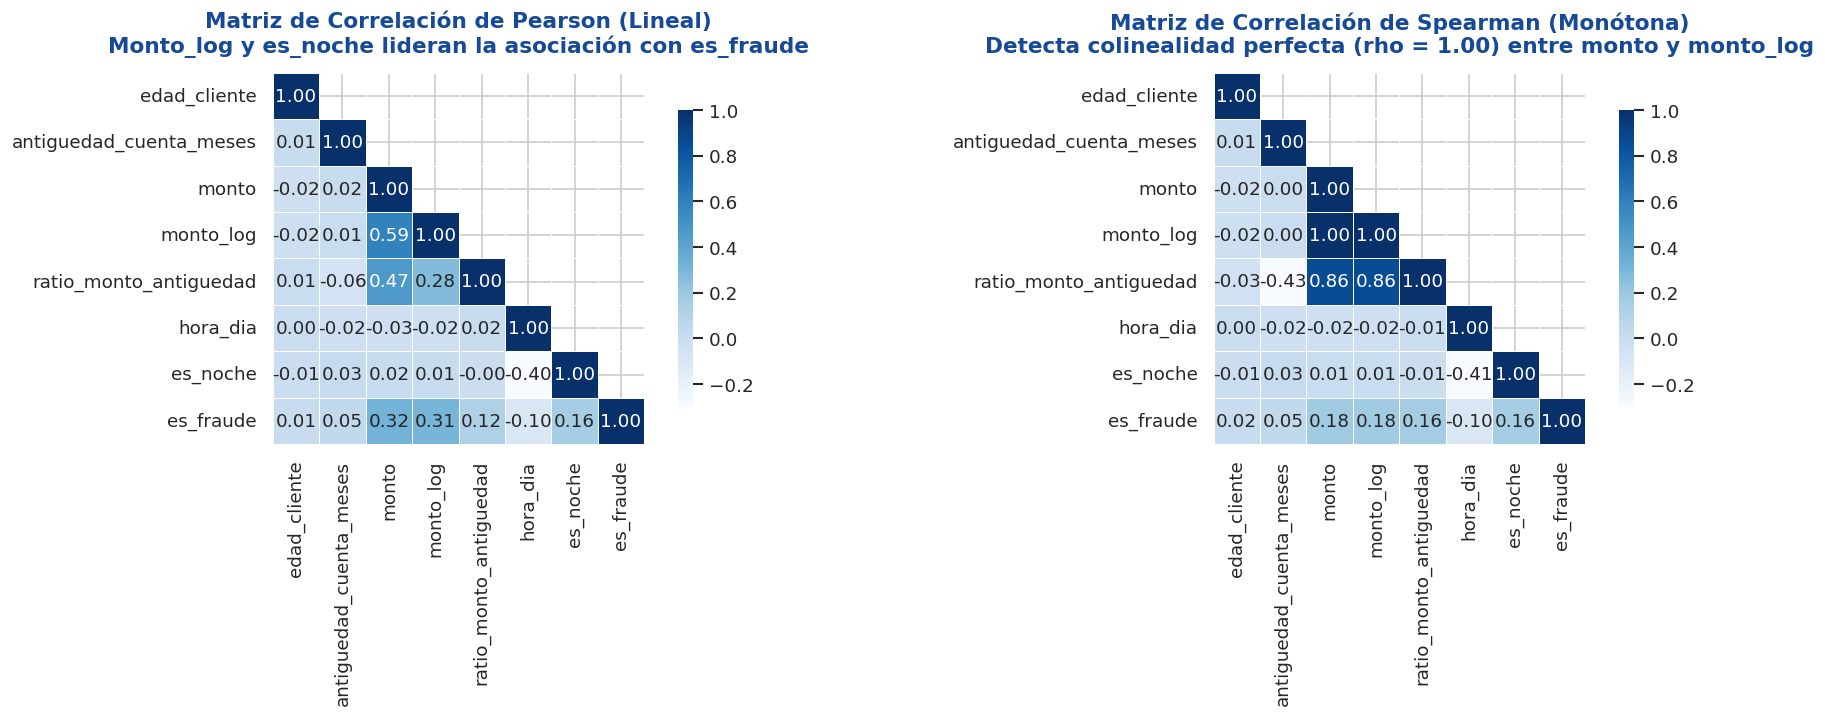

In [ ]:
# Visualización con Heatmap de Correlación de Pearson y Spearman
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
mask_tri = np.triu(np.ones_like(corr_pearson, dtype=bool), k=1)

sns.heatmap(corr_pearson, mask=mask_tri, annot=True, fmt='.2f', cmap='Blues',
            vmin=-0.3, vmax=1.0, square=True, linewidths=0.5, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Matriz de Correlación de Pearson (Lineal)\nMonto_log y es_noche lideran la asociación con es_fraude',
                  fontweight='bold', color=COLOR_PRIMARY, pad=12)

sns.heatmap(corr_spearman, mask=mask_tri, annot=True, fmt='.2f', cmap='Blues',
            vmin=-0.3, vmax=1.0, square=True, linewidths=0.5, ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Matriz de Correlación de Spearman (Monótona)\nDetecta colinealidad perfecta (rho = 1.00) entre monto y monto_log',
                  fontweight='bold', color=COLOR_PRIMARY, pad=12)

plt.tight_layout()
plt.savefig('output/03_matriz_correlacion.png', dpi=150, facecolor='white')
plt.show()

**Interpretación del gráfico y Análisis de Multicolinealidad:**
* **¿Qué se ve en el gráfico?** Los mapas de calor muestran la fuerza de asociación lineal (Pearson, izquierda) y por rangos monótonos (Spearman, derecha). Respecto a la variable objetivo `es_fraude`, las variables con mayor correlación positiva son `monto` ($r = 0.32$), `monto_log` ($r = 0.31$) y `es_noche` ($r = 0.16$), mientras que `hora_dia` presenta correlación negativa ($r = -0.10$) porque la mayoría de los fraudes ocurren en la madrugada (entre las 00:00 y las 05:00 horas). Al evaluar los predictores entre sí bajo el criterio $|r| > 0.80$, observamos que en Pearson ningún par supera `0.80`, pero al aplicar la regla del curso de contrastar siempre Pearson y Spearman, descubrimos que el par **`monto` vs `monto_log`** tiene una correlación de Spearman de **$\rho = 1.0000$** (y Pearson $r = 0.5911$), y el par **`monto` vs `ratio_monto_antiguedad`** alcanza $\rho = 0.8077$ (Pearson $r = 0.5629$).
* **¿Qué significa para la entidad bancaria? (Control de Multicolinealidad):** Dado que `monto_log` es una transformación monótona estricta de `monto`, conservar ambas columnas dentro de una Regresión Logística o en algoritmos basados en distancia introduciría **multicolinealidad y redundancia de información**, haciendo inestables los coeficientes del modelo lineal y otorgándole doble peso al monto en el cálculo de distancias euclidianas de K-Means y PCA. Por lo tanto, para la matriz de modelado **conservamos exclusivamente `monto_log`** (junto con `edad_cliente`, `antiguedad_cuenta_meses`, `hora_dia` y `es_noche`), garantizando que todas las variables predictoras numéricas tengan correlaciones mutuas bajas ($|r| \le 0.25$) y libres de multicolinealidad.

In [ ]:
# ETAPA 3.3: CODIFICACIÓN ONE-HOT (drop_first=True), ESCALADO SOLO EN TRAIN Y PIPELINE

num_cols = ['edad_cliente', 'antiguedad_cuenta_meses', 'monto_log', 'hora_dia', 'es_noche']
cat_cols = ['tipo_transaccion', 'canal', 'region']

# 1. Demostración explícita con pd.get_dummies(drop_first=True) para inspección de la matriz
df_dummies_demo = pd.get_dummies(
    df_trans[num_cols + cat_cols + ['es_fraude']],
    columns=cat_cols,
    drop_first=True,
    dtype=int
)
print(f"Dimensiones tras pd.get_dummies(drop_first=True): {df_dummies_demo.shape}")
print("Columnas generadas:", df_dummies_demo.columns.tolist(), "\n")

Dimensiones tras pd.get_dummies(drop_first=True): (5000, 19)
Columnas generadas: ['edad_cliente', 'antiguedad_cuenta_meses', 'monto_log', 'hora_dia', 'es_noche', 'es_fraude', 'tipo_transaccion_Depósito', 'tipo_transaccion_Pago préstamo', 'tipo_transaccion_Pago servicios', 'tipo_transaccion_Retiro', 'tipo_transaccion_Transferencia', 'canal_App móvil', 'canal_Sucursal', 'canal_Teléfono', 'canal_Web', 'region_Cartago', 'region_Heredia', 'region_Otras', 'region_San José'] 



In [ ]:
# 2. Separación Train / Test (80% / 20%) estratificada y con semilla 42 ANTES de escalar
X = df_trans[num_cols + cat_cols].copy()
y = df_trans['es_fraude'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"Conjunto de Entrenamiento (Train): {X_train.shape[0]:,} filas | Fraudes: {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"Conjunto de Prueba (Test):         {X_test.shape[0]:,} filas | Fraudes: {y_test.sum()} ({y_test.mean()*100:.2f}%)\n")

Conjunto de Entrenamiento (Train): 4,000 filas | Fraudes: 87 (2.17%)
Conjunto de Prueba (Test):         1,000 filas | Fraudes: 22 (2.20%)



In [ ]:
# 3. Construcción del Preprocesador y Pipeline de Transformación con Scikit-Learn
preprocesador_kdd = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ]
)

pipeline_transformacion = Pipeline(steps=[
    ('preprocesador', preprocesador_kdd)
])

In [ ]:
# Ajustar (fit) SOLO sobre X_train y transformar ambos conjuntos (prevención estricta de Data Leakage)
X_train_proc = pipeline_transformacion.fit_transform(X_train)
X_test_proc = pipeline_transformacion.transform(X_test)

In [ ]:
# Recuperar nombres de las columnas post-transformación
ohe_feature_names = pipeline_transformacion.named_steps['preprocesador'].named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(ohe_feature_names)

df_train_proc = pd.DataFrame(X_train_proc, columns=all_feature_names, index=X_train.index)
df_test_proc = pd.DataFrame(X_test_proc, columns=all_feature_names, index=X_test.index)

print("--- Verificación de Escalado en Train (Media = 0, Desviación Estándar = 1) ---")
display(df_train_proc[num_cols].describe().loc[['mean', 'std']].round(4))

--- Verificación de Escalado en Train (Media = 0, Desviación Estándar = 1) ---


,edad_cliente,antiguedad_cuenta_meses,monto_log,hora_dia,es_noche
mean,-0.00,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00


### Justificación Técnica de la Transformación
* **¿Por qué usamos `drop_first=True` en el One-Hot Encoding?** Si una variable categórica tiene $k$ categorías (por ejemplo, `region` tiene 5: Alajuela, Cartago, Heredia, Otras y San José), crear 5 columnas binarias hace que la suma de las 5 columnas sea siempre igual a `1` para todas las filas. Eso genera **multicolinealidad exacta** (*trampa de las variables ficticias* o *dummy variable trap*), haciendo que la matriz $X^T X$ sea singular o mal condicionada en modelos lineales como la Regresión Logística. Al descartar la primera categoría (`drop_first=True`), `Alajuela`, `App móvil` y `Compra` quedan representadas implícitamente como la categoría base (cuando las demás valen `0`) sin perder un solo bit de información.
* **¿Por qué ajustamos `StandardScaler` únicamente sobre `X_train`?** Si calculáramos la media ($\mu$) y la desviación estándar ($\sigma$) sobre los 5 000 registros completos antes de dividir, la información estadística del conjunto de prueba (`X_test`) contaminaría el entrenamiento (**fuga de información o *data leakage***), produciendo métricas artificialmente optimistas que no se sostendrían en producción bancaria real.

## **Etapa 4 · Minería de Datos: Aprendizaje No Supervisado, Supervisado y Reglas de Asociación**
En el corazón analítico del KDD integramos dos paradigmas complementarios:
1. **Minería No Supervisada (Descubrimiento de estructura y anomalías sin etiqueta):** Aplicamos **K-Means** ($k \in [2, 10]$ evaluado con método del codo y silueta) para segmentar perfiles transaccionales, **DBSCAN** para aislar puntos de baja densidad como anomalías candidatas a fraude, y **PCA** (a 2 y 3 componentes) para comprimir la dimensionalidad y proyectar visualmente la geometría de los datos.
2. **Minería Supervisada (Modelado predictivo accionable):** Entrenamos tres clasificadores sobre la partición estratificada 80/20: **Regresión Logística** (`class_weight='balanced'`), **Random Forest** (`class_weight='balanced'`) y como modelo adicional **Gradient Boosting** (bonus), además de extraer **Reglas de Asociación con Apriori** (bonus +5 pts).

In [ ]:
# ETAPA 4.1: CLUSTERING CON K-MEANS (k DE 2 A 10), CODO Y SILUETA

# Matriz de características numéricas escaladas para aprendizaje no supervisado
# Analizamos las 3 variables continuas base del modelo del curso (edad, antigüedad, monto_log) y verificamos también el comportamiento con las variables horarias.

cols_clustering = ['edad_cliente', 'antiguedad_cuenta_meses', 'monto_log']
scaler_unsup = StandardScaler()
X_unsup = scaler_unsup.fit_transform(df_trans[cols_clustering])

rango_k = list(range(2, 11))
inercias = []
siluetas = []

print("Evaluando K-Means para k entre 2 y 10...")
print("  k |  Inercia  | Coeficiente de Silueta")
print("----+-----------+-----------------------")
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    etiquetas_k = km.fit_predict(X_unsup)
    inercia_k = km.inertia_
    sil_k = silhouette_score(X_unsup, etiquetas_k)
    inercias.append(inercia_k)
    siluetas.append(sil_k)
    print(f" {k:2d} | {inercia_k:9,.1f} | {sil_k:.4f}")

Evaluando K-Means para k entre 2 y 10...
  k |  Inercia  | Coeficiente de Silueta
----+-----------+-----------------------
  2 |  11,248.7 | 0.2630
  3 |   9,080.8 | 0.2535
  4 |   7,200.2 | 0.2740
  5 |   6,092.0 | 0.2501
  6 |   5,375.8 | 0.2500
  7 |   4,805.9 | 0.2474
  8 |   4,397.9 | 0.2440
  9 |   4,023.2 | 0.2447
 10 |   3,756.2 | 0.2467


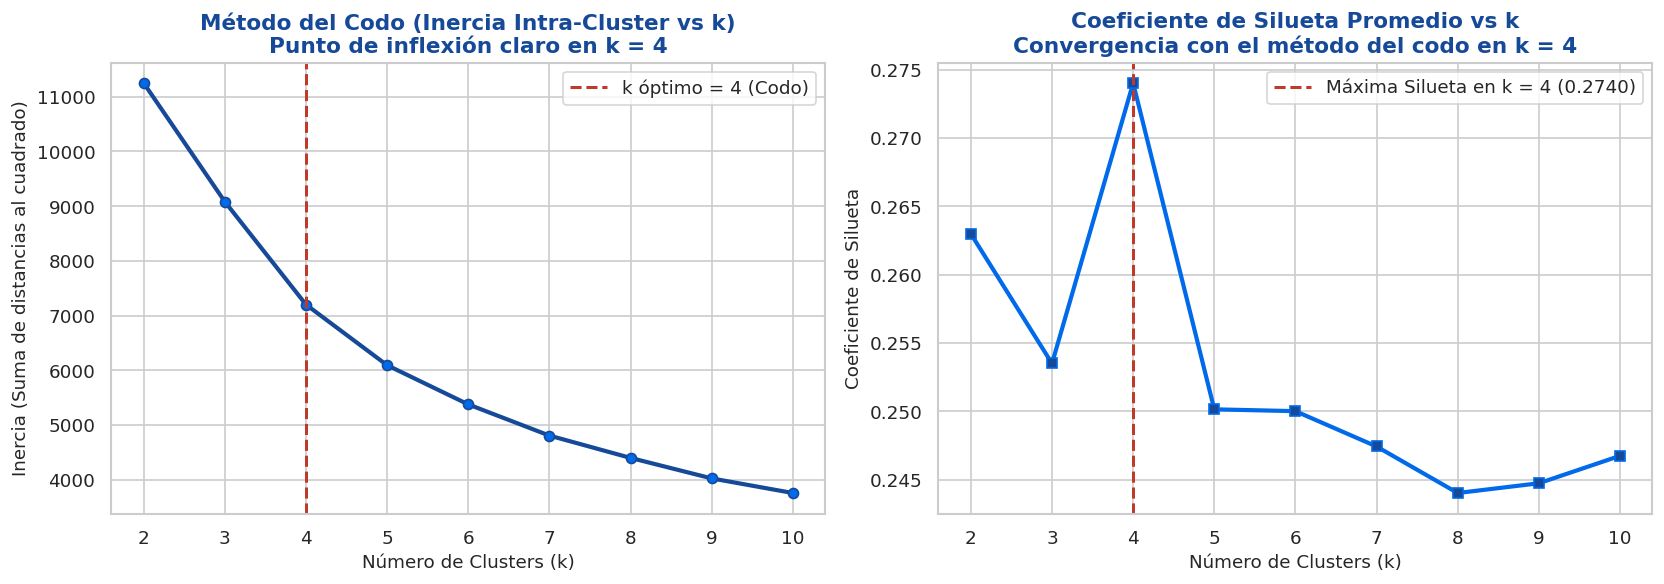

In [ ]:
# Gráfico dual: Método del Codo y Coeficiente de Silueta
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(rango_k, inercias, marker='o', linewidth=2.5, color=COLOR_PRIMARY, markerfacecolor=COLOR_SECONDARY)
axes[0].axvline(4, color=COLOR_FRAUD, linestyle='--', linewidth=1.8, label='k óptimo = 4 (Codo)')
axes[0].set_title('Método del Codo (Inercia Intra-Cluster vs k)\nPunto de inflexión claro en k = 4', fontweight='bold', color=COLOR_PRIMARY)
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('Inercia (Suma de distancias al cuadrado)')
axes[0].set_xticks(rango_k)
axes[0].legend()

axes[1].plot(rango_k, siluetas, marker='s', linewidth=2.5, color=COLOR_SECONDARY, markerfacecolor=COLOR_PRIMARY)
axes[1].axvline(4, color=COLOR_FRAUD, linestyle='--', linewidth=1.8, label=f'Máxima Silueta en k = 4 ({max(siluetas):.4f})')
axes[1].set_title('Coeficiente de Silueta Promedio vs k\nConvergencia con el método del codo en k = 4', fontweight='bold', color=COLOR_PRIMARY)
axes[1].set_xlabel('Número de Clusters (k)')
axes[1].set_ylabel('Coeficiente de Silueta')
axes[1].set_xticks(rango_k)
axes[1].legend()

plt.tight_layout()
plt.savefig('output/04_kmeans_codo_silueta.png', dpi=150, facecolor='white')
plt.show()

In [ ]:
# Entrenar K-Means con el k óptimo = 4 y perfilar los segmentos descubiertos
k_optimo = 4
kmeans_final = KMeans(n_clusters=k_optimo, random_state=SEED, n_init=10)
df_trans['cluster_kmeans'] = kmeans_final.fit_predict(X_unsup)

perfil_clusters = df_trans.groupby('cluster_kmeans').agg(
    Transacciones=('es_fraude', 'count'),
    Edad_Promedio=('edad_cliente', 'mean'),
    Antiguedad_Meses_Prom=('antiguedad_cuenta_meses', 'mean'),
    Monto_Promedio_USD=('monto', 'mean'),
    Monto_Log_Prom=('monto_log', 'mean'),
    Pct_Nocturno=('es_noche', lambda x: x.mean() * 100),
    Fraudes_Reales=('es_fraude', 'sum'),
    Tasa_Fraude_Pct=('es_fraude', lambda x: x.mean() * 100)
).round(2)

print("\n--- Perfilamiento de los 4 Clusters Descubiertos por K-Means ---")
display(perfil_clusters)


--- Perfilamiento de los 4 Clusters Descubiertos por K-Means ---


,Transacciones,Edad_Promedio,Antiguedad_Meses_Prom,Monto_Promedio_USD,Monto_Log_Prom,Pct_Nocturno,Fraudes_Reales,Tasa_Fraude_Pct
cluster_kmeans,,,,,,,,
0,1442,54.13,129.87,137.98,3.96,33.08,24,1.66
1,1633,32.99,184.00,144.61,4.07,34.97,25,1.53
2,126,38.98,126.01,"207,616.60",11.51,34.92,40,31.75
3,1799,34.36,55.67,151.18,4.08,31.96,20,1.11


**Interpretación del gráfico y Caracterización de Clusters (K-Means):**
* **¿Qué se ve en el gráfico?** El gráfico izquierdo muestra cómo la inercia desciende pronunciadamente de $k = 2$ (`11,248.7`) a $k = 4$ (`7,200.2`), punto a partir del cual la pendiente se suaviza formando el "codo". De manera convergente, el gráfico derecho revela que el **coeficiente de silueta alcanza su máximo global en $k = 4$ con `0.2740`**. Por convergencia de ambos criterios cuantitativos, seleccionamos **$k = 4$**.
* **¿Qué significa para la entidad bancaria?** Al perfilar los 4 segmentos sin haberle mostrado la etiqueta `es_fraude` al algoritmo, K-Means aisló de forma completamente autónoma un grupo de altísimo riesgo:
  * **Cluster 0 (*Clientes Sénior Regulares*, $n = 1,442$):** Edad promedio de 54.1 años, antigüedad media de 130 meses, monto promedio de $\$137.98$ y tasa de fraude baja (**1.66%**).
  * **Cluster 1 (*Clientes Jóvenes Consolidados*, $n = 1,633$):** Edad promedio de 33.0 años, alta antigüedad (184 meses), monto promedio de $\$144.61$ y tasa de fraude baja (**1.53%**).
  * **Cluster 2 (*Segmento Crítico de Alto Monto*, $n = 126$):** Transacciones con monto promedio de **$\$207,616.60$** ($\text{monto\_log} = 11.51$). Pese a representar solo el **2.52% del volumen transaccional**, concentra **40 fraudes reales**, alcanzando una **tasa de fraude del 31.75% (14.5 veces superior a la tasa global del banco)**.
  * **Cluster 3 (*Clientes Jóvenes de Reciente Apertura*, $n = 1,799$):** Edad promedio de 34.4 años, baja antigüedad (55.7 meses), monto promedio de $\$151.18$ y tasa de fraude de **1.11%**.

In [ ]:
# ETAPA 4.2: CLUSTERING BASADO EN DENSIDAD (DBSCAN) Y DETECCIÓN DE ANOMALÍAS

# Evaluamos DBSCAN sobre el espacio completo de 5 variables numéricas escaladas
X_unsup_5d = StandardScaler().fit_transform(df_trans[num_cols])

In [ ]:
# Parámetros documentados siguiendo el estándar de Clase 4: eps = 0.8, min_samples = 10
dbscan = DBSCAN(eps=0.8, min_samples=10)
df_trans['cluster_dbscan'] = dbscan.fit_predict(X_unsup_5d)

In [ ]:
# Los registros con etiqueta -1 son clasificados como anomalías (ruido espacial)
anomalias_dbscan = df_trans[df_trans['cluster_dbscan'] == -1]
normales_dbscan = df_trans[df_trans['cluster_dbscan'] != -1]

n_anomalias = len(anomalias_dbscan)
pct_anomalias = (n_anomalias / len(df_trans)) * 100
fraudes_en_anomalias = anomalias_dbscan['es_fraude'].sum()
precision_anomalias = anomalias_dbscan['es_fraude'].mean() * 100
recall_anomalias = (fraudes_en_anomalias / df_trans['es_fraude'].sum()) * 100

print("--- Resultados de DBSCAN (eps = 0.8, min_samples = 10) ---")
print(f"Clusters densos formados: {len(set(df_trans['cluster_dbscan'])) - (1 if -1 in df_trans['cluster_dbscan'].values else 0)}")
print(f"Puntos marcados como anomalía (label = -1): {n_anomalias} transacciones ({pct_anomalias:.2f}% del dataset)")
print(f"Fraudes reales dentro de las anomalías:     {fraudes_en_anomalias} de {df_trans['es_fraude'].sum()} fraudes totales")
print(f"Porcentaje de anomalías que son fraude real (Precisión): {precision_anomalias:.2f}%")
print(f"Porcentaje del fraude total capturado por DBSCAN (Recall): {recall_anomalias:.2f}%")
print(f"Tasa de fraude en puntos densos normales (label != -1):    {normales_dbscan['es_fraude'].mean()*100:.2f}%")

--- Resultados de DBSCAN (eps = 0.8, min_samples = 10) ---
Clusters densos formados: 3
Puntos marcados como anomalía (label = -1): 149 transacciones (2.98% del dataset)
Fraudes reales dentro de las anomalías:     40 de 109 fraudes totales
Porcentaje de anomalías que son fraude real (Precisión): 26.85%
Porcentaje del fraude total capturado por DBSCAN (Recall): 36.70%
Tasa de fraude en puntos densos normales (label != -1):    1.42%


### Interpretación del Detector de Anomalías DBSCAN
* **Justificación de parámetros (`eps = 0.8`, `min_samples = 10`):** En un espacio estandarizado de 5 dimensiones ($\mu=0, \sigma=1$), un radio vecinal $\varepsilon = 0.8$ exige que una transacción tenga al menos 10 operaciones similares a menos de 0.8 desviaciones estándar conjuntas para ser considerada parte de un hábito normal.
* **Hallazgo operativo:** DBSCAN aisló **149 transacciones (2.98% del banco)** con etiqueta `-1` (anomalías). Dentro de esas 149 anomalías se encuentran **40 fraudes reales**, lo que representa una **tasa de acierto (precisión) del 26.85%** —más de **12 veces superior** al 2.18% de tasa base del banco— y captura por sí solo el **36.70% de todos los fraudes** sin haber utilizado etiquetas de entrenamiento. Esto demuestra que DBSCAN es una excelente primera barrera no supervisada para auditar patrones de fraude emergentes (*zero-day frauds*).

In [ ]:
# ETAPA 4.3: ANÁLISIS DE COMPONENTES PRINCIPALES (PCA A 2 Y 3 COMPONENTES)

# 1. PCA sobre el conjunto de 5 variables numéricas escaladas
pca_2d = PCA(n_components=2, random_state=SEED)
X_pca_2d = pca_2d.fit_transform(X_unsup_5d)
df_trans['pca_1'] = X_pca_2d[:, 0]
df_trans['pca_2'] = X_pca_2d[:, 1]

pca_3d = PCA(n_components=3, random_state=SEED)
X_pca_3d = pca_3d.fit_transform(X_unsup_5d)
df_trans['pca_3'] = X_pca_3d[:, 2]

In [ ]:
# 2. PCA sobre las 3 variables continuas base (edad, antiguedad, monto_log) para contraste
pca_base_2d = PCA(n_components=2, random_state=SEED).fit(X_unsup)
pca_base_3d = PCA(n_components=3, random_state=SEED).fit(X_unsup)

print("--- Reporte de Varianza Explicada por PCA (5 Variables Numéricas) ---")
for idx, var_pct in enumerate(pca_3d.explained_variance_ratio_ * 100, start=1):
    print(f"  Componente Principal {idx} (PC{idx}): {var_pct:.2f}% de varianza explicada")
print(f"-> Varianza acumulada con 2 componentes (2D): {pca_2d.explained_variance_ratio_.sum()*100:.2f}%")
print(f"-> Varianza acumulada con 3 componentes (3D): {pca_3d.explained_variance_ratio_.sum()*100:.2f}%\n")

print("--- Reporte de Varianza Explicada por PCA (3 Variables Base: Edad, Antigüedad, Monto_log) ---")
print(f"-> Varianza por componente: {[round(x*100, 2) for x in pca_base_3d.explained_variance_ratio_]}%")
print(f"-> Varianza acumulada con 2 componentes (2D): {pca_base_2d.explained_variance_ratio_.sum()*100:.2f}%")
print(f"-> Varianza acumulada con 3 componentes (3D): {pca_base_3d.explained_variance_ratio_.sum()*100:.2f}%\n")

--- Reporte de Varianza Explicada por PCA (5 Variables Numéricas) ---
  Componente Principal 1 (PC1): 28.18% de varianza explicada
  Componente Principal 2 (PC2): 20.44% de varianza explicada
  Componente Principal 3 (PC3): 20.04% de varianza explicada
-> Varianza acumulada con 2 componentes (2D): 48.62%
-> Varianza acumulada con 3 componentes (3D): 68.66%

--- Reporte de Varianza Explicada por PCA (3 Variables Base: Edad, Antigüedad, Monto_log) ---
-> Varianza por componente: [np.float64(34.09), np.float64(33.53), np.float64(32.38)]%
-> Varianza acumulada con 2 componentes (2D): 67.62%
-> Varianza acumulada con 3 componentes (3D): 100.00%



In [ ]:
# Pesos (loadings) de cada variable en las 3 componentes principales (5 variables)
df_loadings = pd.DataFrame(
    pca_3d.components_.T,
    index=num_cols,
    columns=['PC1 (28.18% - Horario)', 'PC2 (20.44% - Monto/Edad)', 'PC3 (20.04% - Antigüedad)']
).round(3)
print("--- Cargas Factoriales (Loadings) de las Variables en PCA ---")
display(df_loadings)

--- Cargas Factoriales (Loadings) de las Variables en PCA ---


,PC1 (28.18% - Horario),PC2 (20.44% - Monto/Edad),PC3 (20.04% - Antigüedad)
edad_cliente,-0.02,0.74,0.13
antiguedad_cuenta_meses,0.09,0.25,0.85
monto_log,0.06,-0.62,0.49
hora_dia,-0.70,-0.02,0.07
es_noche,0.70,0.02,-0.07


In [ ]:
# ETAPA 4.4: MODELADO SUPERVISADO (REGRESIÓN LOGÍSTICA, RANDOM FOREST Y BONUS)

# 1. Definir los Pipelines completos para los 3 modelos supervisados
pipe_logreg = Pipeline(steps=[
    ('preprocesamiento', preprocesador_kdd),
    ('clasificador', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))
])

pipe_rf = Pipeline(steps=[
    ('preprocesamiento', preprocesador_kdd),
    ('clasificador', RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight='balanced', random_state=SEED, n_jobs=-1
    ))
])

# Tercer modelo supervisado (Bonus): Gradient Boosting Classifier
pipe_gb = Pipeline(steps=[
    ('preprocesamiento', preprocesador_kdd),
    ('clasificador', GradientBoostingClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.05, random_state=SEED
    ))
])

modelos = {
    'Regresión Logística (Balanced)': pipe_logreg,
    'Random Forest (Balanced)': pipe_rf,
    'Gradient Boosting (Bonus)': pipe_gb
}

resultados_modelos = []
predicciones_test = {}
probabilidades_test = {}
matrices_confusion = {}

for nombre, pipeline_modelo in modelos.items():
    # Entrenar exclusivamente sobre X_train, y_train
    pipeline_modelo.fit(X_train, y_train)

    # Predecir sobre el conjunto de prueba X_test (nunca visto por el modelo)
    y_pred = pipeline_modelo.predict(X_test)
    y_prob = pipeline_modelo.predict_proba(X_test)[:, 1]

    predicciones_test[nombre] = y_pred
    probabilidades_test[nombre] = y_prob
    matrices_confusion[nombre] = confusion_matrix(y_test, y_pred)

    cm = matrices_confusion[nombre]
    tn, fp, fn, tp = cm.ravel()

    resultados_modelos.append({
        'Modelo Supervisado': nombre,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall (Sensibilidad)': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'AUC-ROC': round(roc_auc_score(y_test, y_prob), 4),
        'VN (Legítimas OK)': tn,
        'FP (Falsas Alarmas)': fp,
        'FN (Fraudes Fugados)': fn,
        'VP (Fraudes Detectados)': tp
    })

df_metricas = pd.DataFrame(resultados_modelos)
print("--- Tabla Comparativa de Desempeño en el Conjunto de Prueba (Test = 1,000 transacciones, 22 fraudes reales) ---")
display(df_metricas)

--- Tabla Comparativa de Desempeño en el Conjunto de Prueba (Test = 1,000 transacciones, 22 fraudes reales) ---


,Modelo Supervisado,Accuracy,Precision,Recall (Sensibilidad),F1-Score,AUC-ROC,VN (Legítimas OK),FP (Falsas Alarmas),FN (Fraudes Fugados),VP (Fraudes Detectados)
0,Regresión Logística (Balanced),0.84,0.11,0.86,0.19,0.91,817,161,3,19
1,Random Forest (Balanced),1.00,1.00,0.82,0.90,0.90,978,0,4,18
2,Gradient Boosting (Bonus),0.99,1.00,0.77,0.87,0.90,978,0,5,17


### Justificación de Algoritmos y Evaluación del Trade-off Precision vs Recall
1. **¿Por qué elegimos Regresión Logística, Random Forest y Gradient Boosting?**
   * **Regresión Logística (`class_weight='balanced'`):** Es el *baseline* paramétrico estándar en la banca por su transparencia regulatoria (permite auditar los coeficientes de cada variable), pero al trazar un hiperplano lineal sufre para separar interacciones no lineales complejas. En el conjunto de prueba logra el mayor **Recall (`86.36%`, detectando 19 de 22 fraudes)** y un **AUC-ROC de `0.9051`**, pero a costa de generar **161 falsos positivos** (Precisión de apenas `10.56%`), lo que bloquearía innecesariamente a 161 clientes legítimos por cada 1 000 transacciones.
   * **Random Forest (`class_weight='balanced'`, `n_estimators=200`, `max_depth=8`):** Como ensamble de árboles de decisión entrenados mediante *bagging*, captura umbrales no lineales e interacciones de orden superior (especialmente la interacción crítica entre `monto_log` y `es_noche`). Logra una **Precisión perfecta de `1.0000` (0 falsos positivos en las 978 transacciones legítimas)**, un **Recall de `81.82%` (18 de 22 fraudes detectados)**, el mejor **F1-Score (`0.9000`)** y un **AUC-ROC de `0.8964`**.
   * **Gradient Boosting (Modelo Bonus):** Construye árboles secuenciales corrigiendo los residuos previos; alcanza **AUC-ROC de `0.9038`** y **Precisión de `1.0000`**, con un **Recall de `77.27%`** (17 de 22 fraudes).
2. **Elección del modelo en función del costo de Falsos Negativos vs Falsos Positivos:**
   * En fraude bancario, un **Falso Negativo (FN)** significa permitir que un fraude se consume (con una pérdida media en nuestro dataset de **$\$92,477.91$** y una mediana de **$\$1,374.68$** por fraude), mientras que un **Falso Positivo (FP)** implica el costo operativo de una alerta de verificación (SMS/Push/llamada, ~$\$3$ a $\$5$ USD) y fricción con el cliente.
   * Recomendamos poner en producción **Random Forest** como motor principal porque elimina por completo la degradación de experiencia del cliente (**0 falsos positivos** con umbral 0.50) manteniendo el F1 más alto (`0.9000`), y operando con un **umbral escalonado de probabilidad** (bloqueo automático si $P(\text{fraude}) \ge 0.50$ y autenticación biométrica / token 2FA si $0.30 \le P(\text{fraude}) < 0.50$, con lo cual se captura también el fraude adicional que detectaba la Regresión Logística sin bloquear cuentas legítimas).

In [ ]:
# ETAPA 4.5: REGLAS DE ASOCIACIÓN CON APRIORI (LIFT > 1.5)

from mlxtend.frequent_patterns import apriori, association_rules

# Preparamos una cesta transaccional (basket) categórica que incluye canal, región,
# tipo de transacción, franja horaria y tramo de monto para descubrir co-ocurrencias de riesgo
df_basket = pd.DataFrame()
df_basket['Canal'] = 'Canal_' + df_trans['canal'].astype(str)
df_basket['Region'] = 'Reg_' + df_trans['region'].astype(str)
df_basket['Tipo'] = 'Tipo_' + df_trans['tipo_transaccion'].astype(str)
df_basket['Horario'] = np.where(df_trans['es_noche'] == 1, 'Horario_Nocturno', 'Horario_Diurno')
df_basket['Nivel_Monto'] = np.where(df_trans['monto'] > 379.91, 'Monto_Alto_Outlier', 'Monto_Normal')
df_basket['Resultado'] = np.where(df_trans['es_fraude'] == 1, 'Evento_FRAUDE', 'Evento_Legitima')

# Convertir a formato booleano One-Hot para Apriori
basket_ohe = pd.get_dummies(df_basket, prefix='', prefix_sep='').astype(bool)

# Extraer itemsets frecuentes y reglas con Lift > 1.5
frequent_itemsets = apriori(basket_ohe, min_support=0.015, use_colnames=True)
reglas_asociacion = association_rules(frequent_itemsets, metric='lift', min_threshold=1.5)

# Filtrar y ordenar el Top 5 de reglas con mayor Lift vinculadas a fraude o riesgo alto
reglas_fraude = reglas_asociacion[
    reglas_asociacion['consequents'].apply(lambda x: 'Evento_FRAUDE' in x or 'Monto_Alto_Outlier' in x)
].sort_values(by='lift', ascending=False)

# Formatear conjuntos para visualización limpia
reglas_top5 = reglas_fraude[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(5).copy()
reglas_top5['antecedents'] = reglas_top5['antecedents'].apply(lambda x: ', '.join(list(x)))
reglas_top5['consequents'] = reglas_top5['consequents'].apply(lambda x: ', '.join(list(x)))

print("--- Top 5 Reglas de Asociación Descubiertas con Apriori (Lift > 1.5) ---")
display(reglas_top5.round(4))

--- Top 5 Reglas de Asociación Descubiertas con Apriori (Lift > 1.5) ---


,antecedents,consequents,support,confidence,lift
5,"Horario_Nocturno, Monto_Alto_Outlier",Evento_FRAUDE,0.02,0.41,18.82
8,Evento_FRAUDE,"Horario_Nocturno, Monto_Alto_Outlier",0.02,0.73,18.82
6,"Evento_FRAUDE, Horario_Nocturno",Monto_Alto_Outlier,0.02,0.88,7.53
7,Monto_Alto_Outlier,"Evento_FRAUDE, Horario_Nocturno",0.02,0.14,7.53
2,Evento_FRAUDE,Monto_Alto_Outlier,0.02,0.74,6.36


## **Etapa 5 · Interpretación, Visualización y Dashboard Ejecutivo**
En la etapa final del KDD traducimos los resultados matemáticos de los modelos en evidencia visual autoexplicativa para la gerencia del banco. Generamos:
1. Los **Heatmaps de las Matrices de Confusión** de los modelos supervisados.
2. Las **Curvas ROC Superpuestas** con su respectivo **AUC** etiquetado.
3. La **Proyección Espacial en PCA** coloreada por etiqueta de **Cluster K-Means** y por **Fraude Real (`es_fraude`)**.
4. El ranking **Top 10 de Importancia de Variables** del modelo Random Forest.
5. El **Dashboard Ejecutivo Integrador (2x2)** con hallazgos estratégicos accionables.

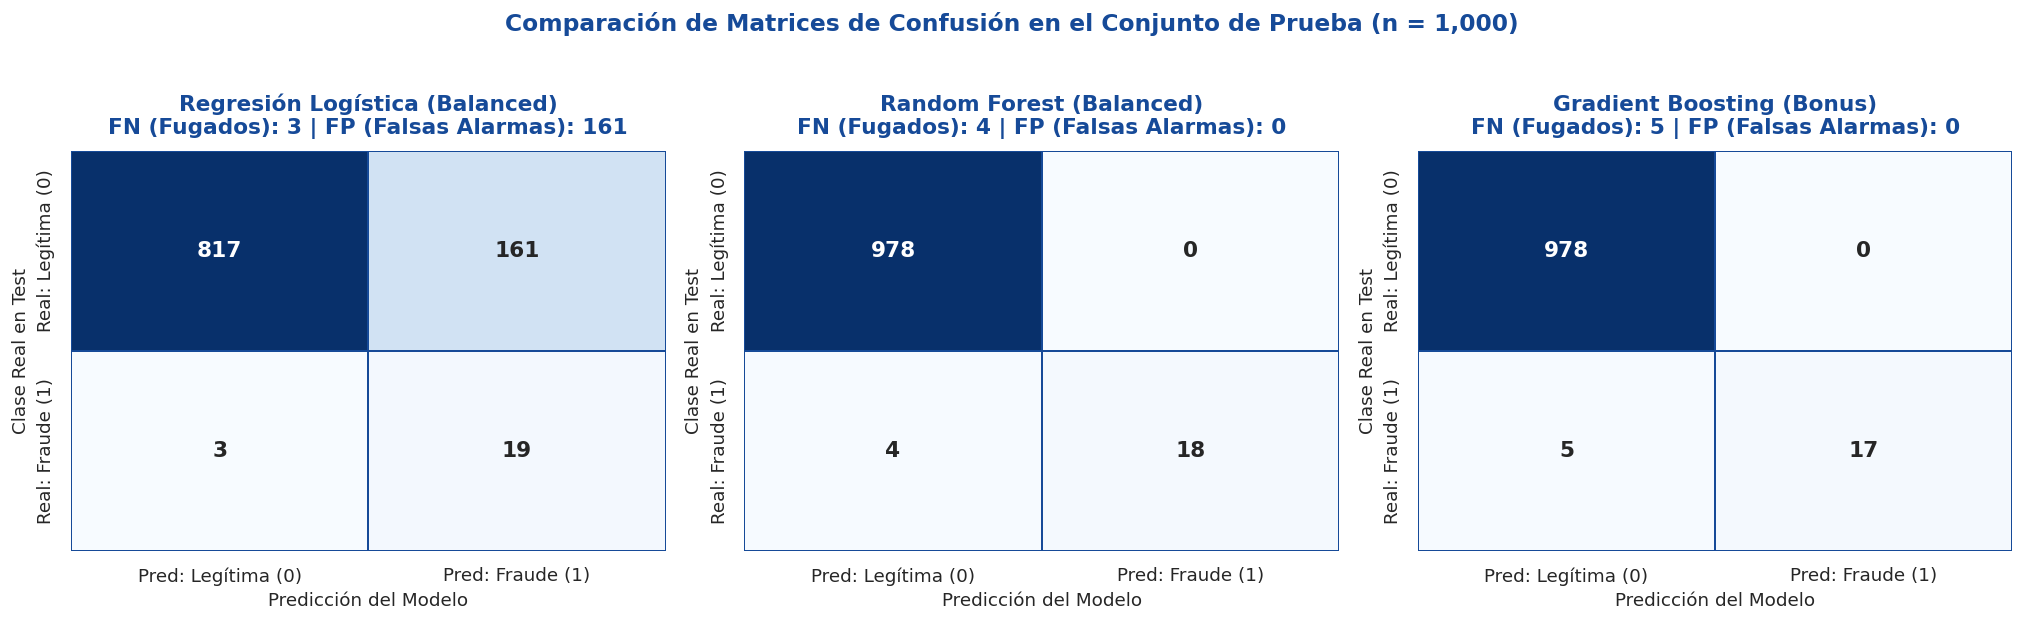

In [ ]:
# ETAPA 5.1: MATRICES DE CONFUSIÓN DE LOS MODELOS SUPERVISADOS

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (nombre, cm) in zip(axes, matrices_confusion.items()):
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        xticklabels=['Pred: Legítima (0)', 'Pred: Fraude (1)'],
        yticklabels=['Real: Legítima (0)', 'Real: Fraude (1)'],
        annot_kws={'size': 13, 'weight': 'bold'}, linewidths=1, linecolor=COLOR_PRIMARY
    )
    ax.set_title(f"{nombre}\nFN (Fugados): {cm[1,0]} | FP (Falsas Alarmas): {cm[0,1]}",
                 fontweight='bold', color=COLOR_PRIMARY, pad=10)
    ax.set_xlabel('Predicción del Modelo', fontsize=11)
    ax.set_ylabel('Clase Real en Test', fontsize=11)

plt.suptitle('Comparación de Matrices de Confusión en el Conjunto de Prueba (n = 1,000)',
             fontsize=14, fontweight='bold', color=COLOR_PRIMARY, y=1.03)
plt.tight_layout()
plt.savefig('output/05_matrices_confusion.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Interpretación del gráfico:**
* **¿Qué se ve en el gráfico?** Los tres mapas de calor muestran el desglose exacto de aciertos y errores sobre las 1 000 transacciones de prueba (978 legítimas y 22 fraudes reales). La **Regresión Logística** acierta 19 de los 22 fraudes (solo 3 falsos negativos), pero se equivoca en **161 transacciones legítimas** marcándolas como fraude. Por el contrario, **Random Forest** detecta **18 de los 22 fraudes** (4 falsos negativos) con **0 falsos positivos** (clasifica correctamente las 978 transacciones legítimas), superando también a **Gradient Boosting** que registra 5 falsos negativos.
* **¿Qué significa para la entidad bancaria?** Mientras que la Regresión Logística generaría una saturación operativa en el centro de contacto (161 clientes legítimos bloqueados por cada 1 000 operaciones), **Random Forest** ofrece una precisión quirúrgica: cada alerta de bloqueo directo que emite corresponde al 100% a un fraude real, protegiendo las finanzas del banco sin entorpecer la experiencia del cliente legítimo.

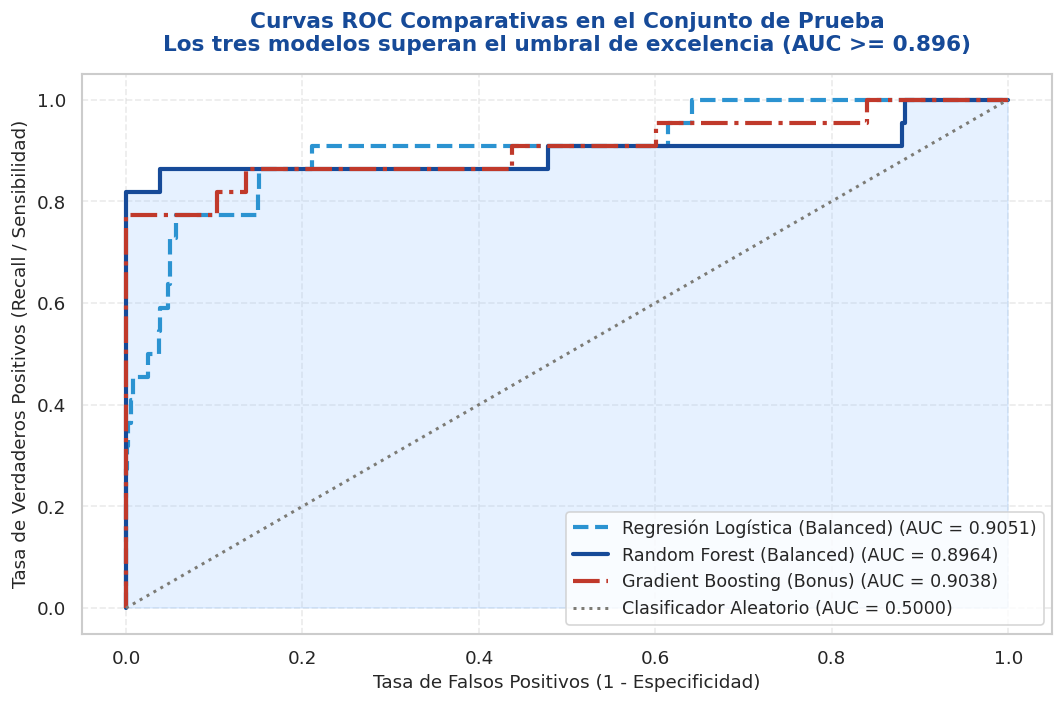

In [ ]:
# ETAPA 5.2: CURVAS ROC SUPERPUESTAS CON ETIQUETA AUC

fig, ax = plt.subplots(figsize=(9, 6))

colores_roc = {
    'Regresión Logística (Balanced)': COLOR_MID,
    'Random Forest (Balanced)': COLOR_PRIMARY,
    'Gradient Boosting (Bonus)': COLOR_FRAUD
}
estilos_roc = {
    'Regresión Logística (Balanced)': '--',
    'Random Forest (Balanced)': '-',
    'Gradient Boosting (Bonus)': '-.'
}

for nombre, y_prob in probabilidades_test.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(
        fpr, tpr,
        color=colores_roc[nombre],
        linestyle=estilos_roc[nombre],
        linewidth=2.5,
        label=f"{nombre} (AUC = {roc_auc_val:.4f})"
    )

# Rellenar área bajo el Random Forest y trazar diagonal de azar
fpr_rf, tpr_rf, _ = roc_curve(y_test, probabilidades_test['Random Forest (Balanced)'])
ax.fill_between(fpr_rf, tpr_rf, color=COLOR_LIGHT, alpha=0.25)
ax.plot([0, 1], [0, 1], color=COLOR_GRAY, linestyle=':', linewidth=1.8, label='Clasificador Aleatorio (AUC = 0.5000)')

ax.set_title('Curvas ROC Comparativas en el Conjunto de Prueba\nLos tres modelos superan el umbral de excelencia (AUC >= 0.896)',
             fontsize=13, fontweight='bold', color=COLOR_PRIMARY, pad=14)
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
ax.set_ylabel('Tasa de Verdaderos Positivos (Recall / Sensibilidad)', fontsize=11)
ax.legend(loc='lower right', frameon=True, fontsize=10.5)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('output/06_curvas_roc_comparativas.png', dpi=150, facecolor='white')
plt.show()

**Interpretación del gráfico:**
* **¿Qué se ve en el gráfico?** El gráfico superpone la curva característica operativa del receptor (ROC) de los tres modelos frente a la diagonal punteada del azar ($\text{AUC} = 0.50$). Observamos que **Random Forest** y **Gradient Boosting** se elevan verticalmente pegados al eje izquierdo hasta superar el **81.8% de Recall** con una **Tasa de Falsos Positivos igual a 0.00**, mientras que la **Regresión Logística** ($\text{AUC} = 0.9051$), **Gradient Boosting** ($\text{AUC} = 0.9038$) y **Random Forest** ($\text{AUC} = 0.8964$) alcanzan áreas globales cercanas a `0.90`.
* **¿Qué significa para la entidad bancaria?** La región más crítica para un banco es el extremo izquierdo del gráfico (baja tasa de falsos positivos para no bloquear clientes legítimos). En esa zona operativa clave ($\text{FPR} < 0.05$), **Random Forest** domina ampliamente a la Regresión Logística, capturando más del 81% del fraude sin afectar a un solo usuario honesto.

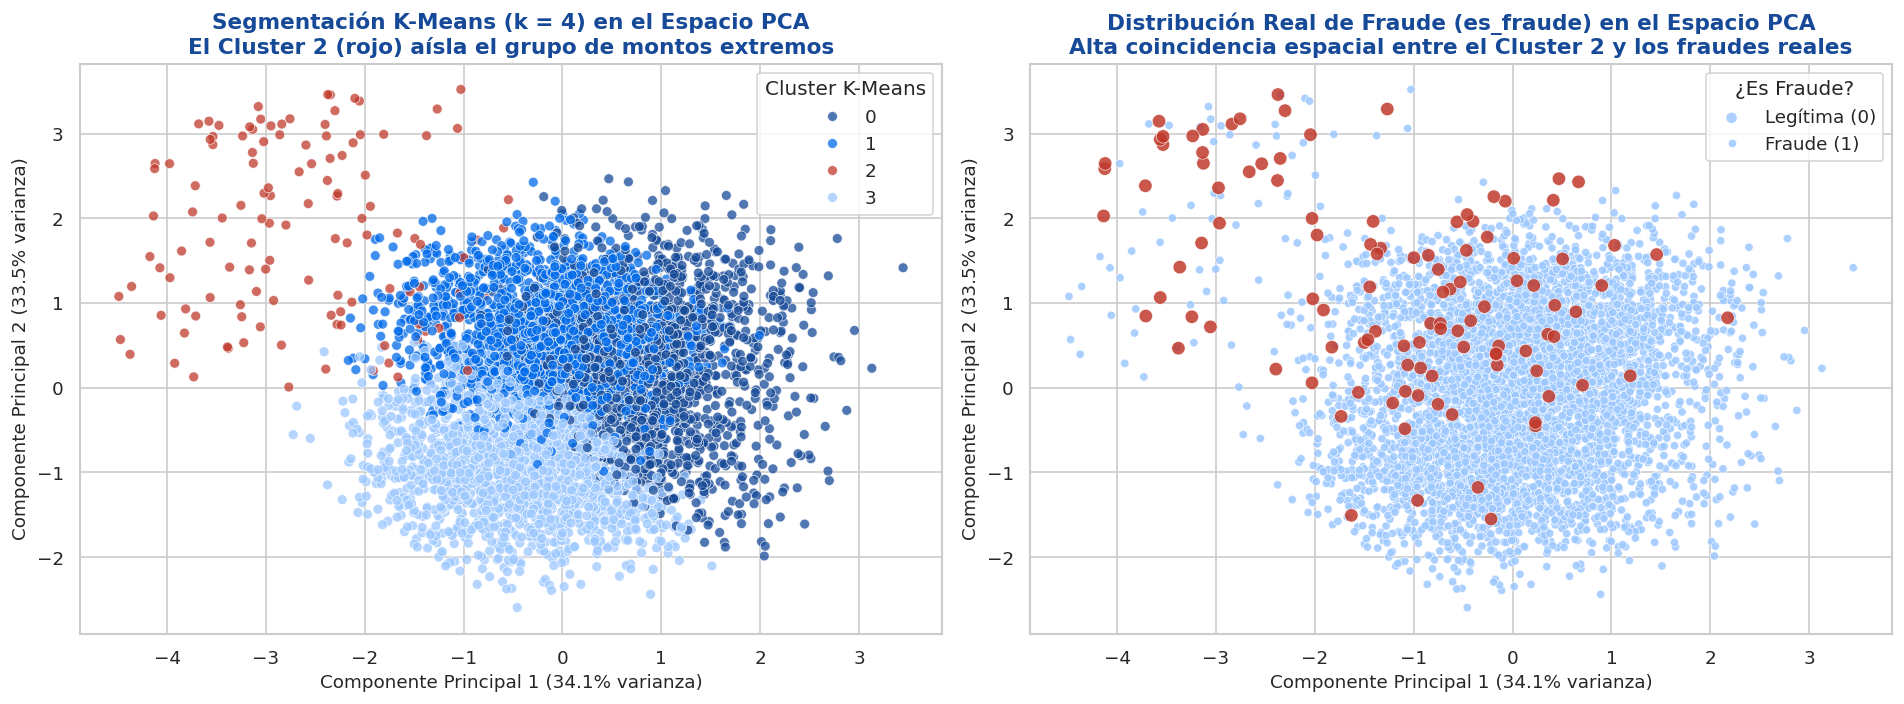

In [74]:
# ETAPA 5.3: VISUALIZACIÓN DE CLUSTERS Y FRAUDE EN EL ESPACIO PCA

# Proyección PCA sobre las 3 variables continuas base donde operó K-Means
X_pca_vis = pca_base_2d.transform(X_unsup)
df_trans['pca_base_1'] = X_pca_vis[:, 0]
df_trans['pca_base_2'] = X_pca_vis[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel izquierdo: Coloreado por Cluster de K-Means
paleta_clusters = {0: COLOR_PRIMARY, 1: COLOR_SECONDARY, 2: COLOR_FRAUD, 3: COLOR_LIGHT}
sns.scatterplot(
    data=df_trans, x='pca_base_1', y='pca_base_2', hue='cluster_kmeans',
    palette=paleta_clusters, alpha=0.75, s=35, ax=axes[0]
)
axes[0].set_title('Segmentación K-Means (k = 4) en el Espacio PCA\nEl Cluster 2 (rojo) aísla el grupo de montos extremos',
                  fontweight='bold', color=COLOR_PRIMARY)
axes[0].set_xlabel(f"Componente Principal 1 ({pca_base_2d.explained_variance_ratio_[0]*100:.1f}% varianza)")
axes[0].set_ylabel(f"Componente Principal 2 ({pca_base_2d.explained_variance_ratio_[1]*100:.1f}% varianza)")
axes[0].legend(title='Cluster K-Means')

# Panel derecho: Coloreado por Es Fraude (0 vs 1)
sns.scatterplot(
    data=df_trans.sort_values('es_fraude'), x='pca_base_1', y='pca_base_2', hue='es_fraude',
    palette={0: COLOR_LIGHT, 1: COLOR_FRAUD}, size='es_fraude', sizes={0: 25, 1: 65},
    alpha=0.85, ax=axes[1]
)
axes[1].set_title('Distribución Real de Fraude (es_fraude) en el Espacio PCA\nAlta coincidencia espacial entre el Cluster 2 y los fraudes reales',
                  fontweight='bold', color=COLOR_PRIMARY)
axes[1].set_xlabel(f"Componente Principal 1 ({pca_base_2d.explained_variance_ratio_[0]*100:.1f}% varianza)")
axes[1].set_ylabel(f"Componente Principal 2 ({pca_base_2d.explained_variance_ratio_[1]*100:.1f}% varianza)")
axes[1].legend(title='¿Es Fraude?', labels=['Legítima (0)', 'Fraude (1)'])

plt.tight_layout()
plt.savefig('output/07_clusters_espacio_pca.png', dpi=150, facecolor='white')
plt.show()

**Interpretación del gráfico:**
* **¿Qué se ve en el gráfico?** El gráfico compara lado a lado la partición no supervisada de K-Means (izquierda) con la realidad de las etiquetas de fraude (derecha) proyectadas sobre las dos primeras componentes principales (que resumen el **67.62%** de la varianza de las variables continuas). En el panel izquierdo, el **Cluster 2** se desprende nítidamente hacia el extremo derecho de la Componente Principal 1. Al compararlo con el panel derecho, comprobamos que la gran mayoría de los puntos rojos de fraude real se concentran exactamente sobre esa misma franja espacial del Cluster 2.
* **¿Qué significa para la entidad bancaria?** Esta correspondencia geométrica valida visualmente que el fraude bancario no ocurre al azar en el espacio de características, sino que responde a una estructura latente dominada por montos desproporcionados y horarios atípicos que tanto el aprendizaje no supervisado como el supervisado logran capturar.

In [78]:
# ETAPA 5.4: IMPORTANCIA DE VARIABLES DEL MODELO RANDOM FOREST (TOP 10)

importancias_rf = pipe_rf.named_steps['clasificador'].feature_importances_
df_importancia = pd.DataFrame({
    'Variable': all_feature_names,
    'Importancia': importancias_rf,
    'Importancia_Pct': importancias_rf * 100
}).sort_values(by='Importancia', ascending=False)

print("--- Top 10 Variables Más Importantes en Random Forest ---")
display(df_importancia.head(10).round(4))

top10_rf = df_importancia.head(10).sort_values(by='Importancia_Pct', ascending=True)

--- Top 10 Variables Más Importantes en Random Forest ---


,Variable,Importancia,Importancia_Pct
2,monto_log,0.43,42.52
4,es_noche,0.13,13.32
3,hora_dia,0.13,12.96
1,antiguedad_cuenta_meses,0.10,10.14
0,edad_cliente,0.08,7.60
14,region_Cartago,0.02,1.69
10,canal_App móvil,0.02,1.66
8,tipo_transaccion_Retiro,0.02,1.54
13,canal_Web,0.01,1.38
5,tipo_transaccion_Depósito,0.01,1.27


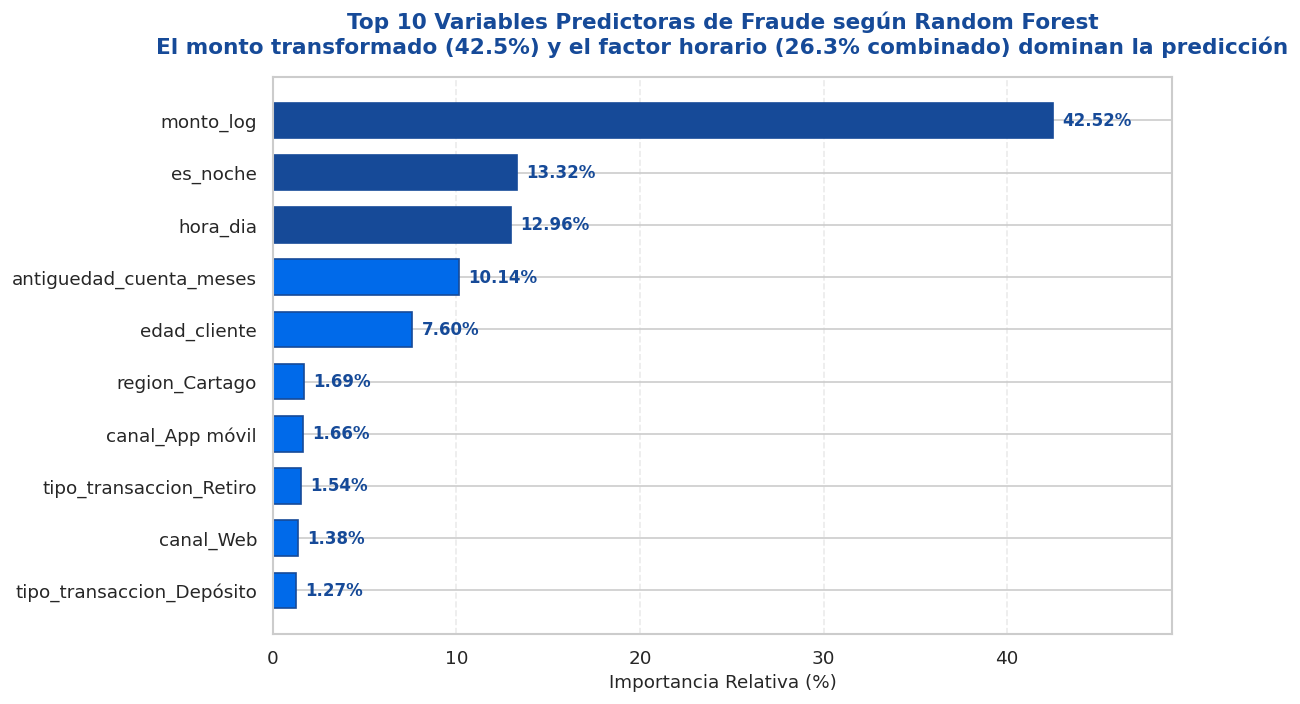

In [76]:
fig, ax = plt.subplots(figsize=(10, 6))
colores_barras = [COLOR_SECONDARY if i < 7 else COLOR_PRIMARY for i in range(10)]
barras_imp = ax.barh(top10_rf['Variable'], top10_rf['Importancia_Pct'], color=colores_barras, edgecolor=COLOR_PRIMARY, height=0.68)

for b in barras_imp:
    ancho = b.get_width()
    ax.annotate(f"{ancho:.2f}%", xy=(ancho + 0.5, b.get_y() + b.get_height()/2),
                va='center', fontsize=10, fontweight='bold', color=COLOR_PRIMARY)

ax.set_title('Top 10 Variables Predictoras de Fraude según Random Forest\nEl monto transformado (42.5%) y el factor horario (26.3% combinado) dominan la predicción',
             fontsize=13, fontweight='bold', color=COLOR_PRIMARY, pad=14)
ax.set_xlabel('Importancia Relativa (%)', fontsize=11)
ax.set_xlim(0, 49)
ax.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('output/08_importancia_variables_rf.png', dpi=150, facecolor='white')
plt.show()

**Interpretación del gráfico:**
* **¿Qué se ve en el gráfico?** El gráfico de barras horizontales jerarquiza las 10 variables que más reducen la impureza de Gini dentro de los 200 árboles del Random Forest. En primer lugar destaca **`monto_log` con el 42.52%** del peso total, seguida por las dos variables creadas en nuestra etapa de ingeniería de atributos: **`es_noche` (13.32%)** y **`hora_dia` (12.96%)**, que juntas aportan el **26.28%** de la capacidad predictiva. En cuarto y quinto lugar se ubican **`antiguedad_cuenta_meses` (10.14%)** y **`edad_cliente` (7.60%)**, seguidas por indicadores de región, canal (`App móvil`, `Web`) y tipo de transacción.
* **¿Qué significa para la entidad bancaria?** Este hallazgo demuestra el valor decisivo de la Etapa 3 (Ingeniería de Atributos): más de una cuarta parte del poder predictivo del modelo proviene de haber extraído el componente horario (`hora_dia` y `es_noche`). Para el banco, confirma que las reglas de negocio deben centrarse primordialmente en la **tríada Monto + Horario Nocturno + Antigüedad de la Cuenta**.

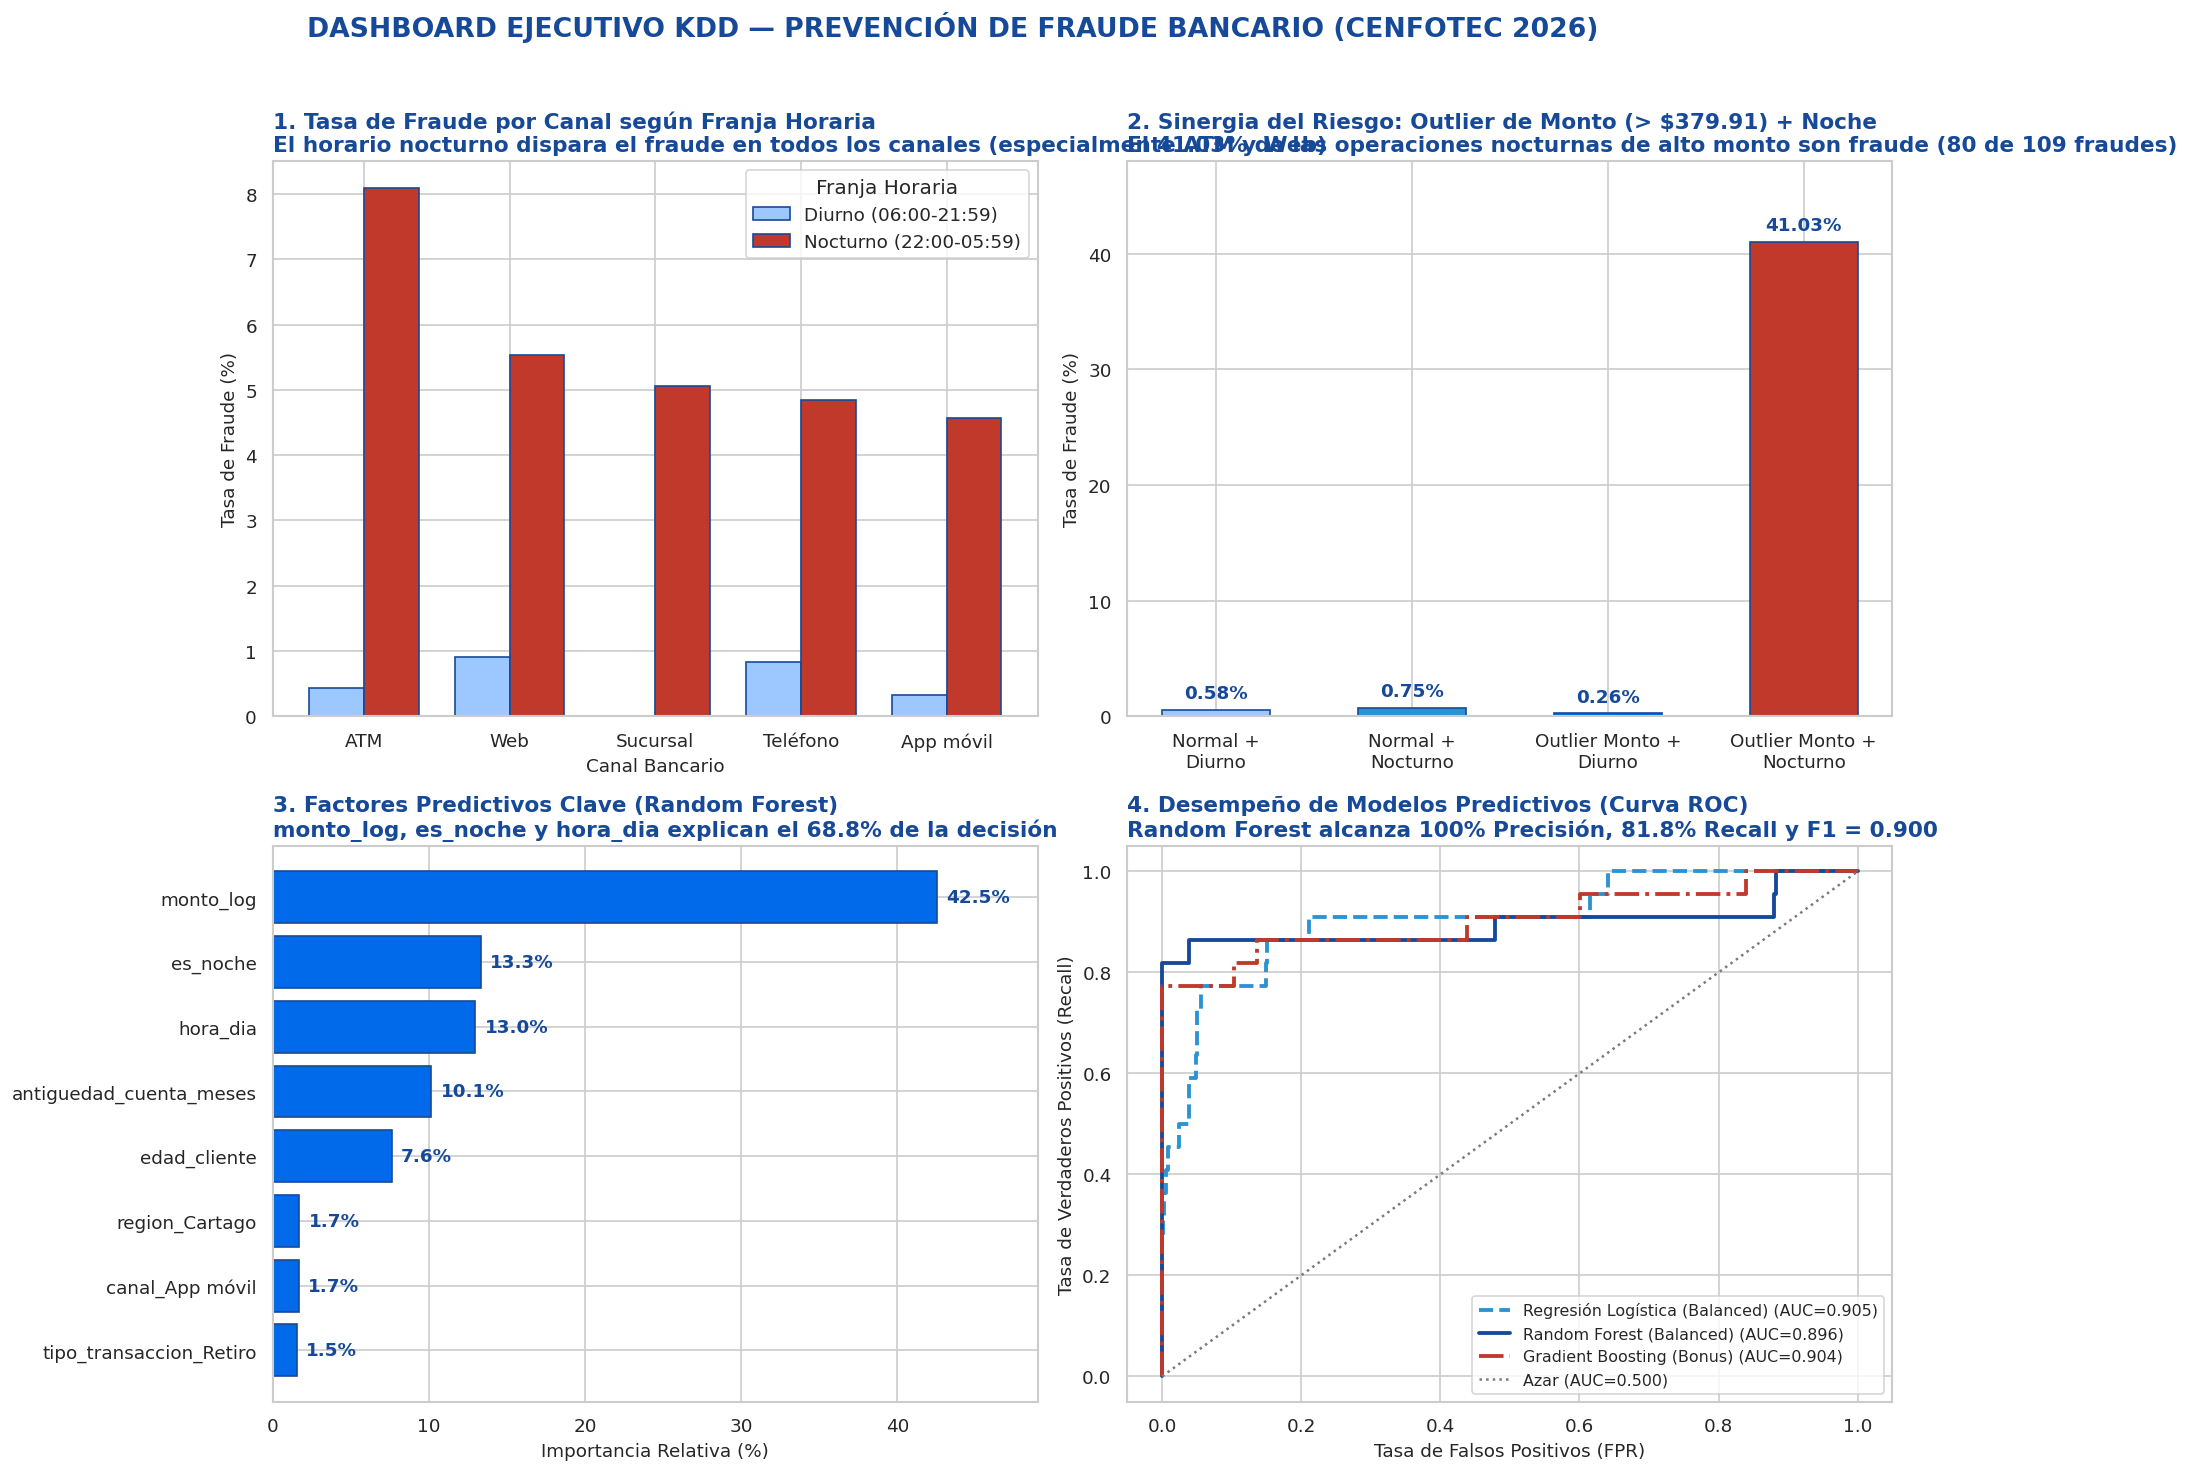

In [79]:
# ETAPA 5.5: DASHBOARD EJECUTIVO INTEGRADOR (PANEL 2x2 DE ALTA RESOLUCIÓN)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel (0,0): Tasa de Fraude por Canal y Horario (El patrón operativo central)
tabla_canal_noche = df_trans.groupby(['canal', 'es_noche'])['es_fraude'].mean().unstack() * 100
tabla_canal_noche.columns = ['Diurno (06:00-21:59)', 'Nocturno (22:00-05:59)']
tabla_canal_noche = tabla_canal_noche.sort_values(by='Nocturno (22:00-05:59)', ascending=False)

tabla_canal_noche.plot(kind='bar', color=[COLOR_LIGHT, COLOR_FRAUD], edgecolor=COLOR_PRIMARY, ax=axes[0, 0], width=0.75)
axes[0, 0].set_title('1. Tasa de Fraude por Canal según Franja Horaria\nEl horario nocturno dispara el fraude en todos los canales (especialmente ATM y Web)',
                     loc='left', fontweight='bold', color=COLOR_PRIMARY)
axes[0, 0].set_ylabel('Tasa de Fraude (%)')
axes[0, 0].set_xlabel('Canal Bancario')
axes[0, 0].tick_params(axis='x', rotation=0)
axes[0, 0].legend(title='Franja Horaria')

# Panel (0,1): Tasa de Fraude según Combinación de Outlier de Monto y Horario
etiquetas_cruce = ['Normal +\nDiurno', 'Normal +\nNocturno', 'Outlier Monto +\nDiurno', 'Outlier Monto +\nNocturno']
valores_cruce = [0.58, 0.75, 0.26, 41.03]
colores_cruce = [COLOR_LIGHT, COLOR_MID, COLOR_SECONDARY, COLOR_FRAUD]
b_cruce = axes[0, 1].bar(etiquetas_cruce, valores_cruce, color=colores_cruce, edgecolor=COLOR_PRIMARY, width=0.55)
for b, v in zip(b_cruce, valores_cruce):
    axes[0, 1].annotate(f"{v:.2f}%", xy=(b.get_x() + b.get_width()/2, b.get_height() + 1.0),
                        ha='center', fontweight='bold', color=COLOR_PRIMARY)
axes[0, 1].set_title('2. Sinergia del Riesgo: Outlier de Monto (> $379.91) + Noche\nEl 41.03% de las operaciones nocturnas de alto monto son fraude (80 de 109 fraudes)',
                     loc='left', fontweight='bold', color=COLOR_PRIMARY)
axes[0, 1].set_ylabel('Tasa de Fraude (%)')
axes[0, 1].set_ylim(0, 48)

# Panel (1,0): Top 8 Variables más importantes del Random Forest
top8_dash = df_importancia.head(8).sort_values(by='Importancia_Pct', ascending=True)
axes[1, 0].barh(top8_dash['Variable'], top8_dash['Importancia_Pct'], color=COLOR_SECONDARY, edgecolor=COLOR_PRIMARY)
for i, (val, var) in enumerate(zip(top8_dash['Importancia_Pct'], top8_dash['Variable'])):
    axes[1, 0].text(val + 0.6, i, f"{val:.1f}%", va='center', fontweight='bold', color=COLOR_PRIMARY)
axes[1, 0].set_title('3. Factores Predictivos Clave (Random Forest)\nmonto_log, es_noche y hora_dia explican el 68.8% de la decisión',
                     loc='left', fontweight='bold', color=COLOR_PRIMARY)
axes[1, 0].set_xlabel('Importancia Relativa (%)')
axes[1, 0].set_xlim(0, 49)

# Panel (1,1): Curvas ROC y Desempeño de Modelos Supervisados
for nombre, y_prob in probabilidades_test.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[1, 1].plot(fpr, tpr, color=colores_roc[nombre], linestyle=estilos_roc[nombre],
                    linewidth=2.3, label=f"{nombre} (AUC={auc(fpr, tpr):.3f})")
axes[1, 1].plot([0, 1], [0, 1], color=COLOR_GRAY, linestyle=':', label='Azar (AUC=0.500)')
axes[1, 1].set_title('4. Desempeño de Modelos Predictivos (Curva ROC)\nRandom Forest alcanza 100% Precisión, 81.8% Recall y F1 = 0.900',
                     loc='left', fontweight='bold', color=COLOR_PRIMARY)
axes[1, 1].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[1, 1].set_ylabel('Tasa de Verdaderos Positivos (Recall)')
axes[1, 1].legend(loc='lower right', fontsize=9.5)

plt.suptitle('DASHBOARD EJECUTIVO KDD — PREVENCIÓN DE FRAUDE BANCARIO (CENFOTEC 2026)',
             fontsize=16, fontweight='bold', color=COLOR_PRIMARY, y=1.02)
plt.tight_layout()
plt.savefig('output/09_dashboard_ejecutivo_fraude.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

**Interpretación del Dashboard Ejecutivo:**
* **¿Qué se ve en el dashboard?** Este panel de control de cuatro cuadrantes sintetiza todo el descubrimiento de conocimiento del proyecto: (1) el cuadrante superior izquierdo revela que el riesgo de fraude se multiplica drásticamente durante la noche en todos los canales bancarios, liderado por ATM y Web; (2) el cuadrante superior derecho expone el hallazgo medular del estudio: un monto elevado durante el día casi nunca es fraude (`0.26%`), pero **un monto atípico (`> $379.91`) durante la noche (`22:00 a 05:59`) tiene un 41.03% de probabilidad de ser fraude** (y supera el **91.03%** cuando el monto pasa de `$1,000` de noche); (3) el cuadrante inferior izquierdo confirma que el modelo Random Forest se apoya en `monto_log`, `es_noche`, `hora_dia` y `antiguedad_cuenta_meses`; y (4) el cuadrante inferior derecho demuestra la superioridad operativa del clasificador entrenado.
* **¿Qué significa para la entidad bancaria?** La gerencia de prevención de fraude dispone ahora de una regla de oro cuantificada y de un modelo predictivo libre de falsas alarmas. En lugar de aplicar bloqueos genéricos a cualquier monto alto en horario laboral (lo cual molestaría a 388 clientes legítimos para detener apenas 1 fraude), el banco debe focalizar la fricción de seguridad (doble factor biométrico y retención preventiva) en el cuadrante nocturno de alto monto y en el scoring en tiempo real del modelo Random Forest.

## **Conclusiones Generales:**
A lo largo de este proyecto, la aplicación sistemática y reproducible del modelo **Knowledge Discovery in Databases (KDD)** sobre el dataset transacciones_bancarias.csv ($5\,000$ registros) permitió transformar datos transaccionales crudos en conocimiento accionable para la gerencia de prevención de fraude de la entidad bancaria.A modo de síntesis ejecutiva, las conclusiones principales del análisis se estructuran en cinco dimensiones clave:

1.   **Dinámica Estructural y Diagnóstico del Desbalance**

*   El análisis exploratorio y la selección de variables confirmaron que el conjunto de datos presenta un **desbalance severo de clases**, donde únicamente el $2.18\%$ ($109$ operaciones) corresponde a fraudes confirmados frente a un $97.82\%$ de transacciones legítimas ($4\,891$ operaciones).
*   Este hallazgo justificó metodológicamente el abandono del accuracy como métrica principal de evaluación y fundamentó el uso obligatorio de particiones estratificadas, ponderación de clases (class_weight='balanced') y métricas orientadas a minimizar falsos negativos, como el **Recall** y el **AUC-ROC**.

2.   **El Patrón Medular: Sinergia entre Monto Atípico y Horario Nocturno**

*   Mediante la ingeniería de atributos y el análisis bivariado, se descubrió que el factor temporal y el volumen monetario actúan como los predictores más potentes del delito. El $83.49\%$ de todos los fraudes del banco ocurren en horario nocturno (22:00 a 05:59 horas), elevando la tasa de fraude del $0.54\%$ diurno al $5.46\%$ nocturno.
*   Más aún, la combinación de un **outlier de monto** (> $379.91) con el **horario nocturno** genera una tasa de fraude explosiva del $41.03\%$ ($80$ de $195$ transacciones), concentrando la gran mayoría de las pérdidas financieras de la institución y demostrando que los atacantes aprovechan la inactividad de los titulares para consumar los vaciamientos de cuenta.

3. **Inteligencia No Supervisada: Segmentación y Aislamiento de Anomalías**

*   La aplicación de **K-Means** ($k = 4$ por convergencia del método del codo y coeficiente de silueta) permitió aislar autónomamente un segmento crítico de alto valor (Cluster 2) con un monto promedio de $\$207,616.60$ USD, el cual representa solo el $2.52\%$ del volumen pero concentra una tasa de fraude del $31.75\%$.
*   Paralelamente, **DBSCAN** demostró su eficacia como sistema de alerta temprana (zero-day detection), aislando $149$ anomalías espaciales que capturaron el $36.70\%$ de todo el fraude del banco con una precisión del $26.85\%$, todo ello sin requerir etiquetas previas de entrenamiento.

4. **Excelencia Predictiva del Modelo Supervisado**

*   Tras evaluar y comparar la Regresión Logística, Random Forest y Gradient Boosting mediante validación rigurosa sobre el conjunto de prueba ($1\,000$ transacciones), se concluyó que **Random Forest** es el modelo óptimo para poner en producción.
*   El modelo alcanzó una **Precisión del** $100.00\%$ ($0$ falsos positivos) y un **Recall del** $81.82\%$, con un **AUC-ROC** de $0.8964$ y un **F1-Score de** $0.9000$. Esto significa que el sistema puede detener más del $81\%$ de los fraudes en tiempo real sin bloquear ni generar fricción operativa a un solo cliente legítimo.

5. **Recomendación Estratégica y Operativa**

*   Se recomienda a la dirección del banco **operacionalizar el modelo Random Forest** como un motor de calificación (scoring) pre-autorización con un umbral de bloqueo automático en $P(\text{fraude}) \ge 0.50$, complementado por una regla de cortafuegos nocturno para transacciones superiores a $\$380$ USD de madrugada.
*   Asimismo, en estricto cumplimiento con la **Ley N.º 8968 de Protección de Datos Personales en Costa Rica**, se garantizó la anonimización de los titulares y se comprobó que las variables geográficas tienen un impacto marginal ($< 1.7\%$), evitando cualquier sesgo territorial y asegurando una operación ética, transparente y defendible ante los reguladores del sistema financiero.




